In [1]:
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/impport_packages.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/simulation_class.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/create_world.ipynb"

#### Setting up environmental parameters

In [2]:

folder = Path("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/finegrain_100_100_env/wo_stdfitness/epi")

epi_obj = {}

for path in folder.glob("*.csv"):
    print(path)

    # extract dimension from filename
    match = re.search(r"dims(\d+)", path.stem)
    if match:
        dim = int(match.group(1))

        df = pd.read_csv(path).iloc[:, 1:]  # remove first column
        epi_obj[f"epi_{dim}"] = df


epi_obj["epi_20"] = pd.read_csv("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/finegrain_100_100_env/wo_stdfitness/epi/rhos100_ms100_gens10000_dims20_mutrate0.001.csv")
epi_obj["epi_35"] = pd.read_csv("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/finegrain_100_100_env/wo_stdfitness/epi/rhos100_ms100_gens10000_dims35_mutrate0.001.csv")
print(epi_obj.keys())

folder = Path("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/finegrain_100_100_env/wo_stdfitness/onlygen")

onlygen_obj = {}

for path in folder.glob("*.csv"):
    print(path)

    match = re.search(r"dims(\d+)", path.stem)
    if match:
        dim = int(match.group(1))

        df = pd.read_csv(path).iloc[:, 1:]
        onlygen_obj[f"gen_{dim}"] = df

onlygen_obj["gen_35"] = pd.read_csv("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/finegrain_100_100_env/wo_stdfitness/onlygen/rhos100_ms100_gens10000_dims35_mutrate0.001_onlygen.csv")


print(onlygen_obj.keys())

dims = [1,2,3,5,10,20,35]

FileNotFoundError: [Errno 2] No such file or directory: '/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/finegrain_100_100_env/wo_stdfitness/epi/rhos100_ms100_gens10000_dims20_mutrate0.001.csv'

In [ ]:
rho_cases = 30
m_cases=  30
maxgen= 50000
popsize = 5000
                                 
initial_memory = 0
full_env_values = create_world(rho_cases, m_cases, maxgen)   # create world (input: generations, no. rhos and no. ms) 
print('shape of scenarios with nas:',full_env_values.shape)

clean_data_env = full_env_values[~np.isnan(full_env_values).any(axis=1)]
print('shape of scenarios without nas:',clean_data_env.shape)

nof_scenarios = np.shape(clean_data_env)[0]

print('nof examined "worlds" or scenarios:', nof_scenarios) 

gens = np.arange(1, maxgen +1 )
print('number of generations teh simulation is run for', maxgen) 



shape of scenarios with nas: (900, 50004)
shape of scenarios without nas: (625, 50004)
nof examined "worlds" or scenarios: 625
number of generations teh simulation is run for 50000


In [ ]:
clean_data_env.shape

(625, 50004)

In [ ]:
np.isnan(clean_data_env).sum()

np.int64(0)

In [ ]:
np.savetxt("clean_data_env_50.txt", clean_data_env, delimiter="\t", fmt="%.8g")

In [ ]:
chunk_size = 100
chunks = [clean_data_env[i:i + chunk_size] for i in range(0, len(clean_data_env), chunk_size)]
#output_path = "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Plot_results/chunks_1k.npy"

np.save("chunks_10k_8_50.npy", np.array(chunks, dtype=object))
len(chunks)

In [ ]:
data =  np.load('/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Plot_results/chunks_50k_compressed.npz',allow_pickle=True)

In [ ]:
chunks = np.load("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Plot_results/chunks_10k_7.npy", allow_pickle=True)
task_id =3 
array_scenarios_chunk = chunks[task_id]
array_scenarios_chunk[:,4:]

array([[0., 1., 1., ..., 1., 1., 1.],
       [0., 0., 0., ..., 1., 1., 1.],
       [0., 1., 0., ..., 1., 0., 0.],
       ...,
       [0., 1., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.]], shape=(1000, 10000))

In [ ]:
rows_per_job = 100
start_row = task_id * rows_per_job  # 200
end_row = min(start_row + rows_per_job, 6976)  # 300 or 6976
n_rows = end_row - start_row  # 100 (or fewer for last job)

file_path = '/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Plot_results/clean_data_env.txt'

# Read only the needed chunk
params_df = pd.read_csv(
    file_path,
    sep='\t',
    skiprows=range(1, start_row + 1),  # skip all rows *before* start_row (header at 0)
    nrows=n_rows,
    header= None
)


In [ ]:

# Test specific chunks
print(f"Total chunks: {len(chunks)}")
print(f"Chunk 0 size: {len(chunks[6])}")


Total chunks: 7
Chunk 0 size: 919


In [ ]:
dims = get_cube_dims(20)

N = create_cube(popsize, dims=dims, nof_dimensions=20, epsilon=0.05, initial_memory=initial_memory)

In [ ]:

max_gen= 50000
popsize = 5000

# Mutation rates: [epi-memory mutation rate, geno mutation rate]
mutrate = [0.001, 0.001]

# Mutation sizes: [epi-memory mutation size, geno mutation size]
mutsize = [1, 1]

epsilon = 0.05 # phenotypic noise


In [ ]:
chunk_size = 10000
chunks = [clean_data_env[i:i + chunk_size] for i in range(0, len(clean_data_env), chunk_size)]
np.save("chunks_50k_7.npy", np.array(chunks, dtype=object))

In [ ]:
len(chunks)

7

In [ ]:
seed_array = np.linspace(0, 10000, num=chunks[6].shape[0], dtype=int)
    # Create all combinations of sigma_mut and sigma_alpha
param_grid = [
        (scenario, seed, popsize, 5000000, dims, N, mutsize, mutrate, epsilon, 20, False) #only genetics can either be True or false
        for scenario, seed in zip(chunks[6], seed_array) #where each row corresponds to one scenario
    ]


In [ ]:
len(param_grid)

919

#### Evolution of transgenerational memory across environmental conditions

In [ ]:
for i in dims:
    
    df_epi = epi_obj[f"epi_{i}"]
    df_gen = onlygen_obj[f"gen_{i}"]   # adjust key if needed

    # --- (0,0) fitness ---
    pivoted_fitness = df_epi.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)
    
    df_gen = onlygen_obj[f"gen_{i}"]   # adjust key if needed

    fig, ax = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(
        f"Fitness and Evolved Transgenerational memory strength, no. of dimensions {i}",
        fontsize=16
    )
    fig.subplots_adjust(top=0.90)

    cmap1 = plt.cm.copper.copy()
    cmap1.set_bad(color='gray')
    cmap2 = plt.cm.viridis.copy()
    cmap2.set_bad(color='gray')
    max_abs = np.nanmax(np.abs(pivoted_fitness.values))
    min_abs = np.nanmin(np.abs(pivoted_fitness.values))
    
    norm = mcolors.Normalize(vmin=max_abs, vmax=min_abs)
    
    
    pcm1 = ax[0,0].pcolormesh(
        pivoted_fitness.columns,
        pivoted_fitness.index,
        pivoted_fitness.values,
        cmap=cmap1, norm=norm, shading='auto'
    )
    fig.colorbar(pcm1, ax=ax[0,0],
                 label='Fitness (W) with Transgenerational memory',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[0,0].set_title(r'Fitness with Transgenerational-memory')
    ax[0,0].set_ylabel('mean time spent in first environment')
    ax[0,0].set_xlabel('autocorrelation of environment')
    
    # --- (0,1) genetic fitness ---
    pivoted_gen = df_gen.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)

    pcm2 = ax[0,1].pcolormesh(
        pivoted_gen.columns,
        pivoted_gen.index,
        pivoted_gen.values,
        cmap=cmap1, norm=norm, shading='auto'
    )
    fig.colorbar(pcm2, ax=ax[0,1],
                 label='Fitness (W) only genetics',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[0,1].set_title('Genetic fitness')
    ax[0,1].set_ylabel('mean time spent in first environment')
    ax[0,1].set_xlabel('autocorrelation of environment')

    # --- (1,0) epimem ---
    pivoted_epi = df_epi.pivot_table(
        index='m', columns='rho', values='epi_mem_p'
    ).sort_index().sort_index(axis=1)

    pcm3 = ax[1,0].pcolormesh(
        pivoted_epi.columns,
        pivoted_epi.index,
        pivoted_epi.values,
        cmap=cmap2,  shading='auto'
    )
    fig.colorbar(pcm3, ax=ax[1,0],
                 label='Evolved Transgenerational-memory strength',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[1,0].set_title('Transgenerational-memory')
    ax[1,0].set_ylabel('mean time spent in first environment')
    ax[1,0].set_xlabel('autocorrelation of environment')

    # --- (1,1) neutral ---
    pivoted_neutral = df_epi.pivot_table(
        index='m', columns='rho', values='neutral_trait_p'
    ).sort_index().sort_index(axis=1)

    pcm4 = ax[1,1].pcolormesh(
        pivoted_neutral.columns,
        pivoted_neutral.index,
        pivoted_neutral.values,
        cmap=cmap2, shading='auto'
    )
    fig.colorbar(pcm4, ax=ax[1,1],
                 label='Neutral trait',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[1,1].set_title('Neutral trait')
    ax[1,1].set_ylabel('mean time spent in first environment')
    ax[1,1].set_xlabel('autocorrelation of environment')

        

    plt.tight_layout()
    plt.savefig(f'/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Figures/finegrain_dims/dim{i}_finegrain.png')
    plt.show()
    
    # Complete figure with both positive/negative + proper axes
    plt.figure(figsize=(10, 6))
    plt.plot(df_epi['epi_mem_p'], df_epi['fitness'], 'ro', linewidth=3, markersize=8)
    plt.xlabel('Transgenerational memory', fontsize=14)
    plt.ylabel('fitness' , fontsize=12)
    #plt.ylim(0,1)
    #plt.yscale('log')
    plt.title(f'Dimension {i}', fontsize=16)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()

KeyError: 'epi_memory'

#### Count worlds with high memory and low mem

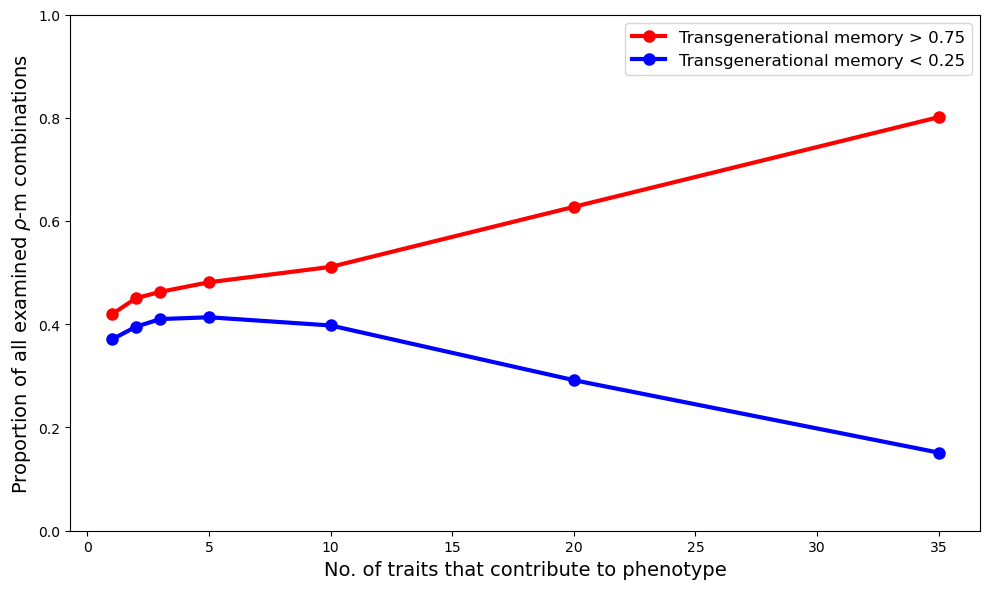

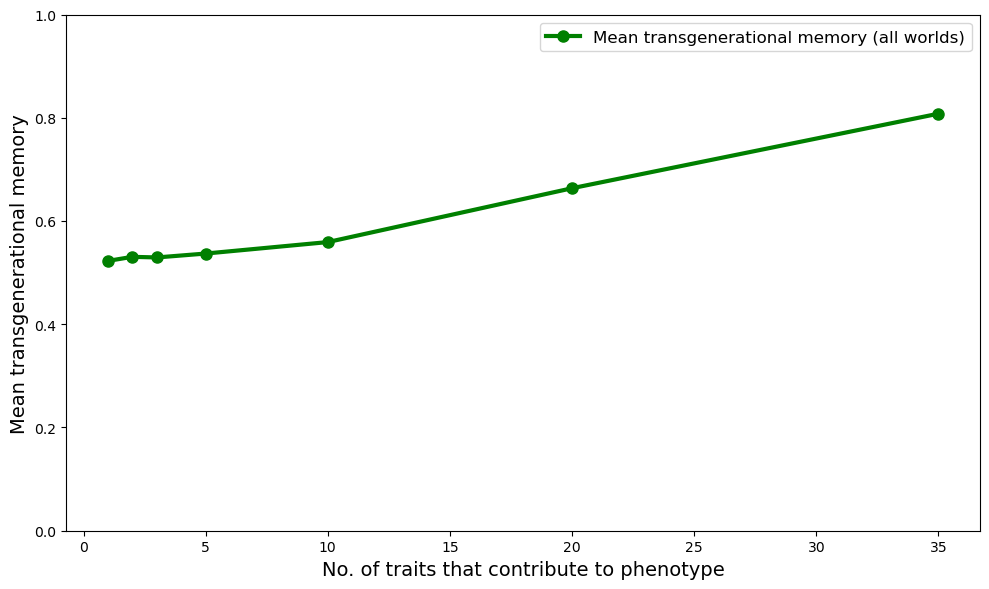

In [ ]:
hi_low_mem = []
dim_mean_memory = []

for i in dims:
    
    df_epi = epi_obj[f"epi_{i}"]
    
    # Without subsetting - use full dataframe
    subset_worlds = df_epi.shape[0]
    
    prop_hi = (df_epi['epi_mem_p'] > 0.75).sum() / subset_worlds
    prop_low = (df_epi['epi_mem_p'] < 0.25).sum() / subset_worlds
    
    hi_low_mem.append(np.array([i, prop_hi, prop_low]))
    
    dim_mean_memory.append(np.array([i, df_epi['epi_mem_p'].mean()]))

# Rest remains the same
dim = np.array([d[0] for d in hi_low_mem])
prop_hi_array = np.array([d[1] for d in hi_low_mem])
prop_lo_array = np.array([d[2] for d in hi_low_mem])

plt.figure(figsize=(10, 6))
plt.plot(dim, prop_hi_array, 'ro-', linewidth=3, markersize=8, label='Transgenerational memory > 0.75')
plt.plot(dim, prop_lo_array, 'bo-', linewidth=3, markersize=8, label='Transgenerational memory < 0.25')
plt.xlabel('No. of traits that contribute to phenotype', fontsize=14)
plt.ylabel(rf"Proportion of all examined $\rho$-m combinations ", fontsize=14)  # Updated label
plt.ylim(0,1)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# Mean plot stays the same
dim_mean = np.array([d[0] for d in dim_mean_memory])
mean_epi = np.array([d[1] for d in dim_mean_memory])

plt.figure(figsize=(10, 6))
plt.plot(dim_mean, mean_epi, 'go-', linewidth=3, markersize=8, label='Mean transgenerational memory (all worlds)')
plt.xlabel('No. of traits that contribute to phenotype', fontsize=14)
plt.ylabel("Mean transgenerational memory", fontsize=14)
plt.ylim(0,1)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

#### Comparing evolved memory an neutral trait between dimensions

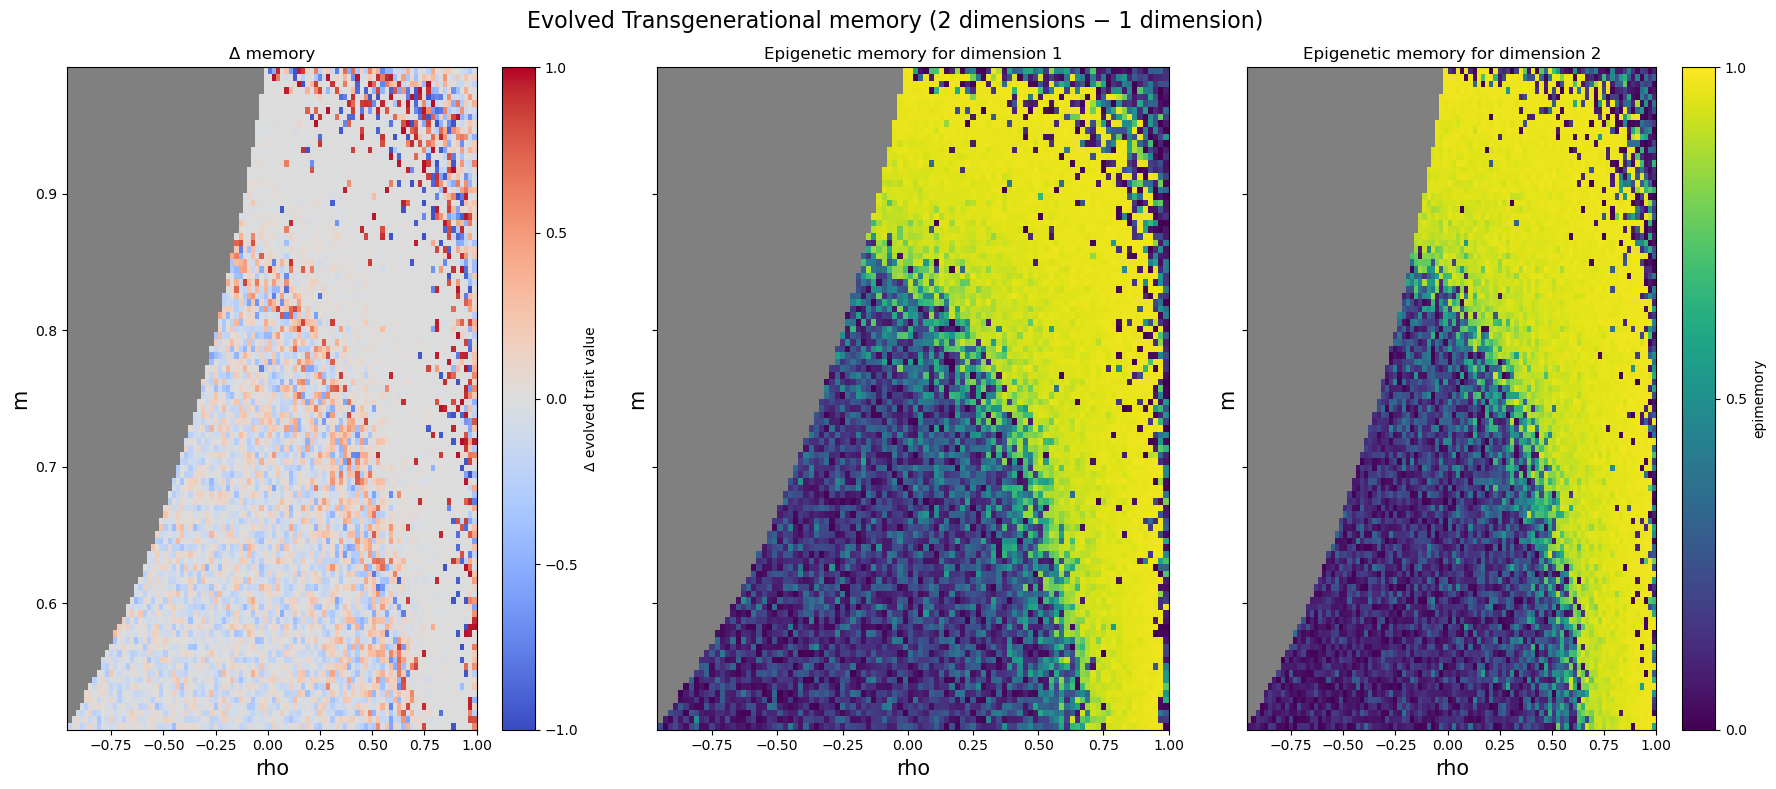

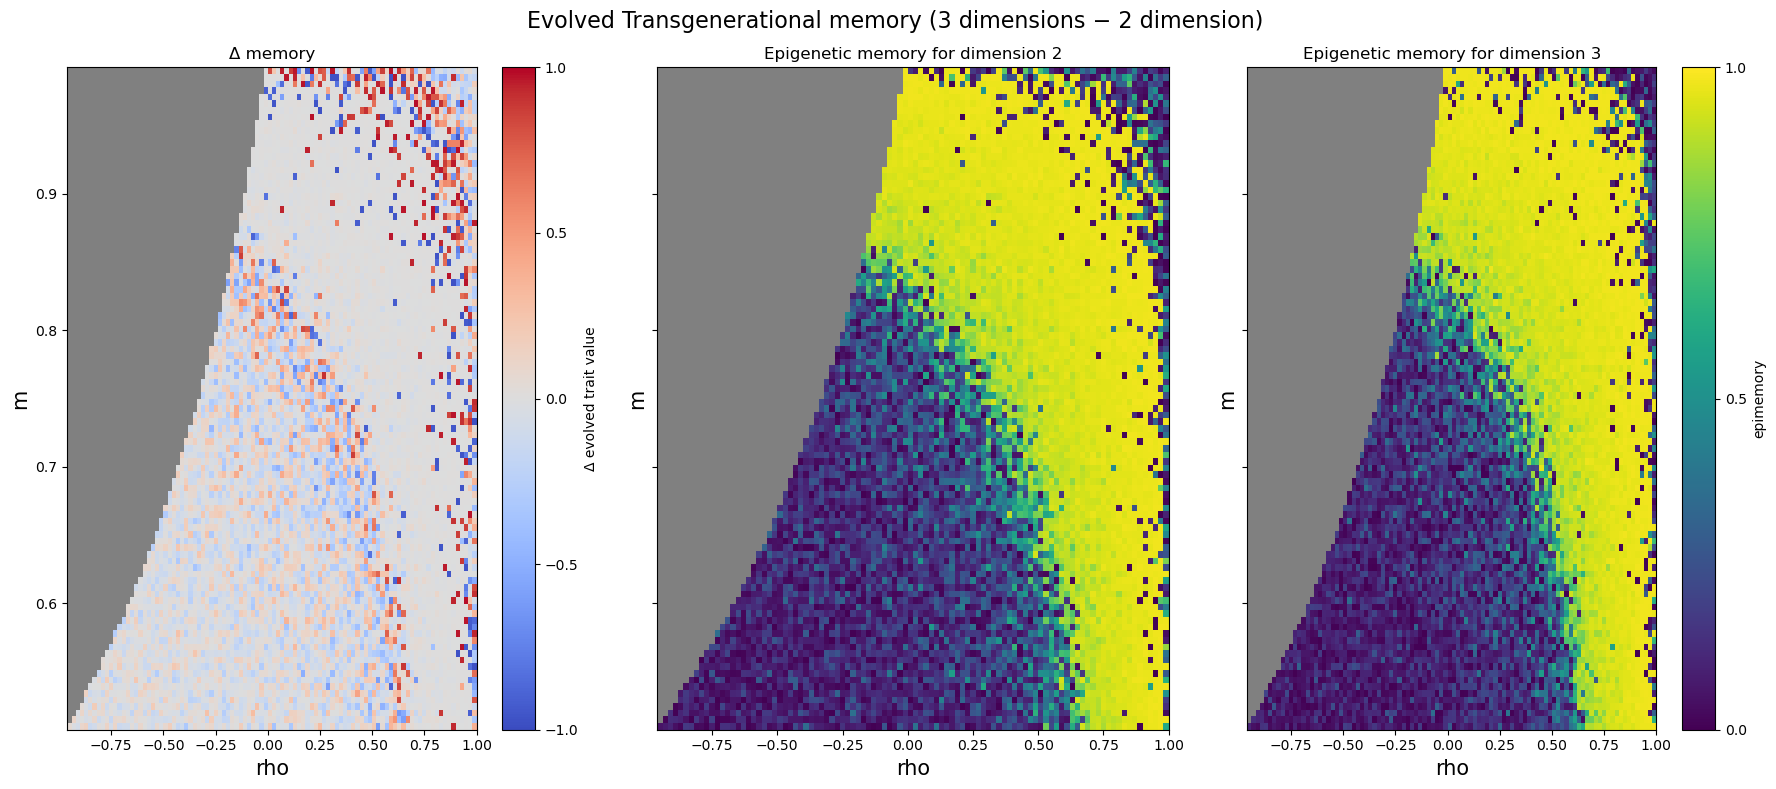

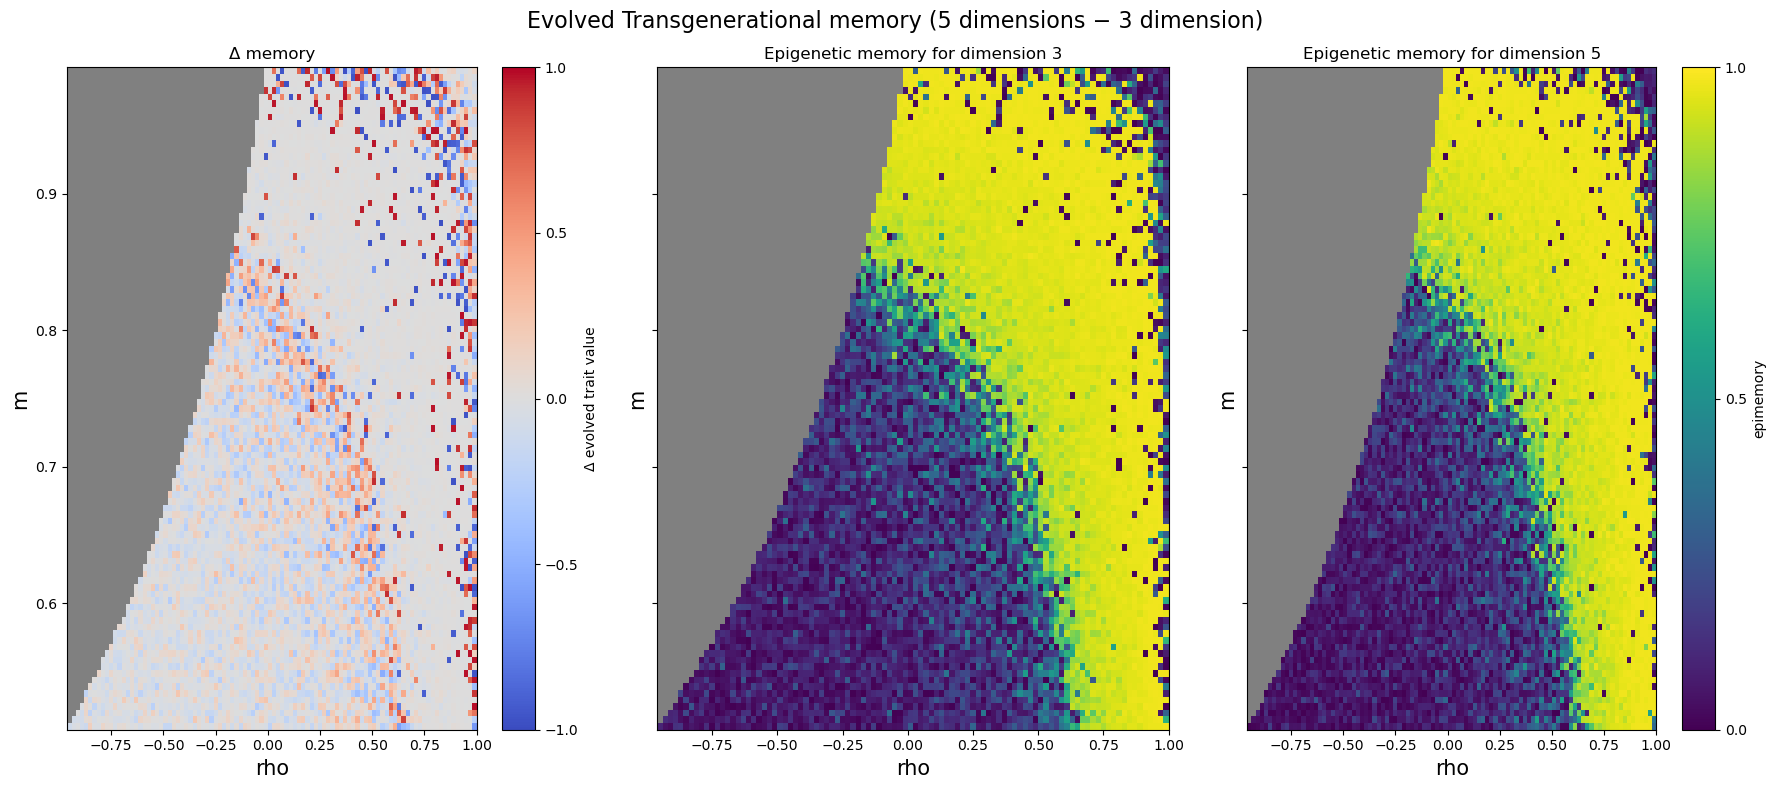

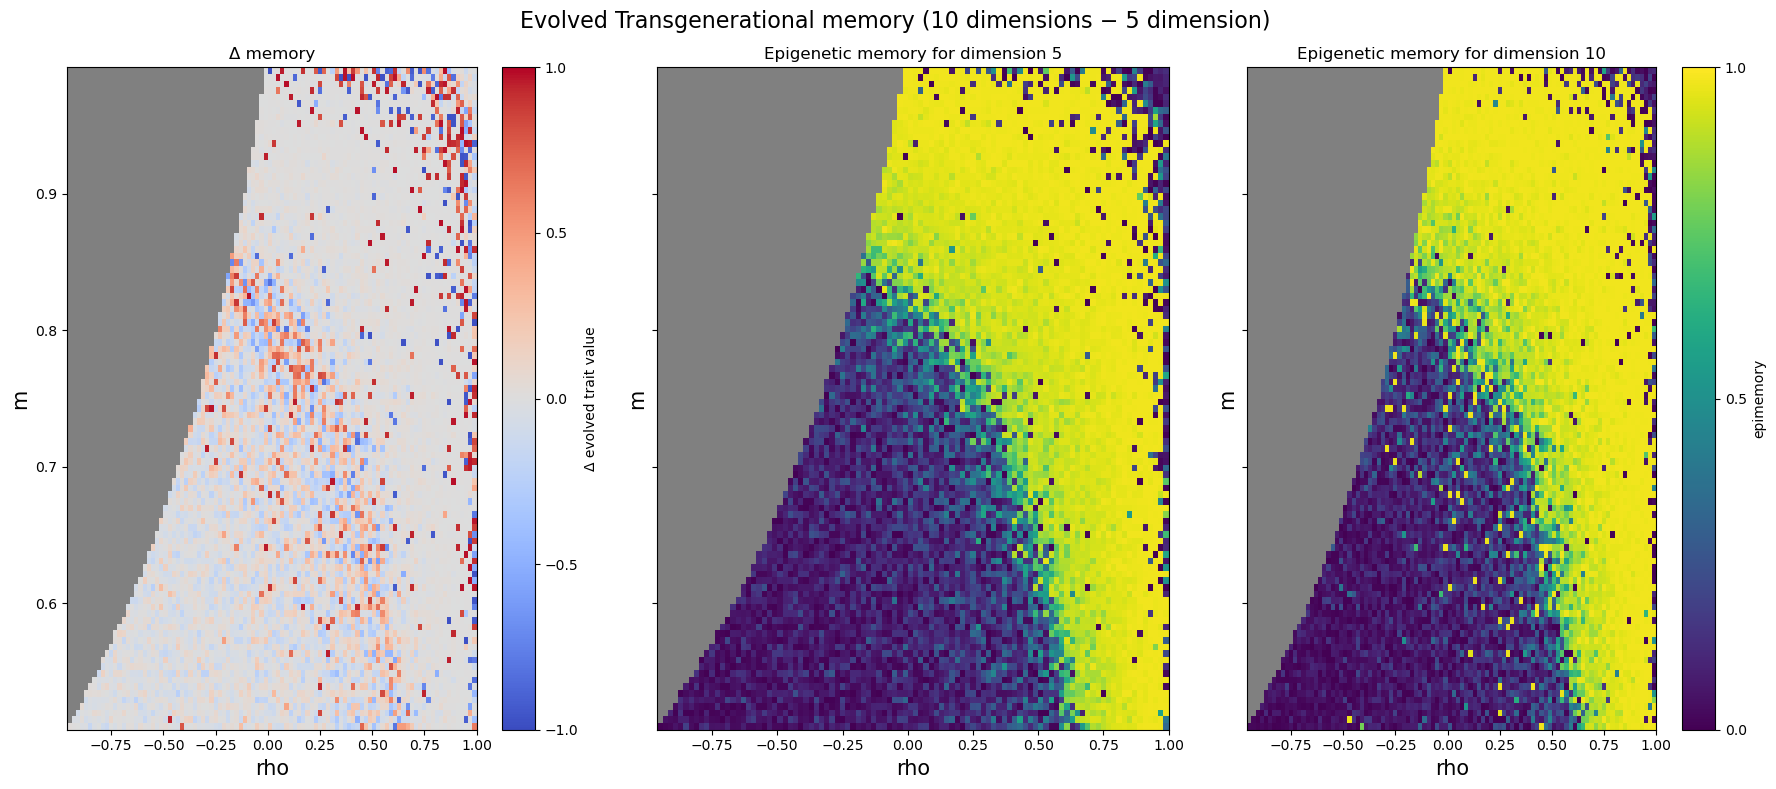

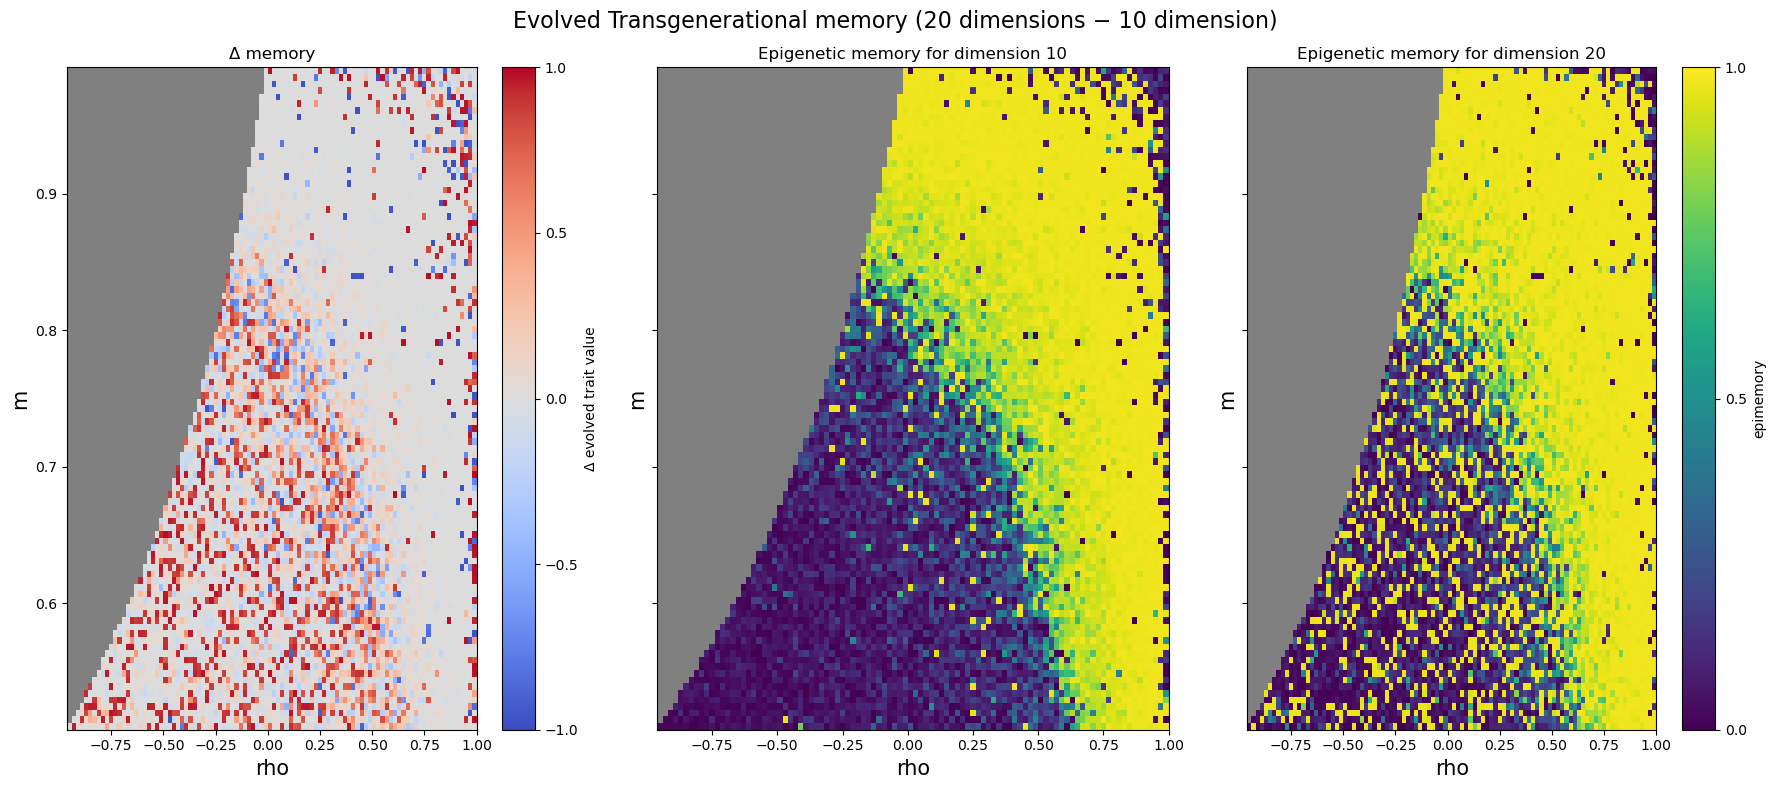

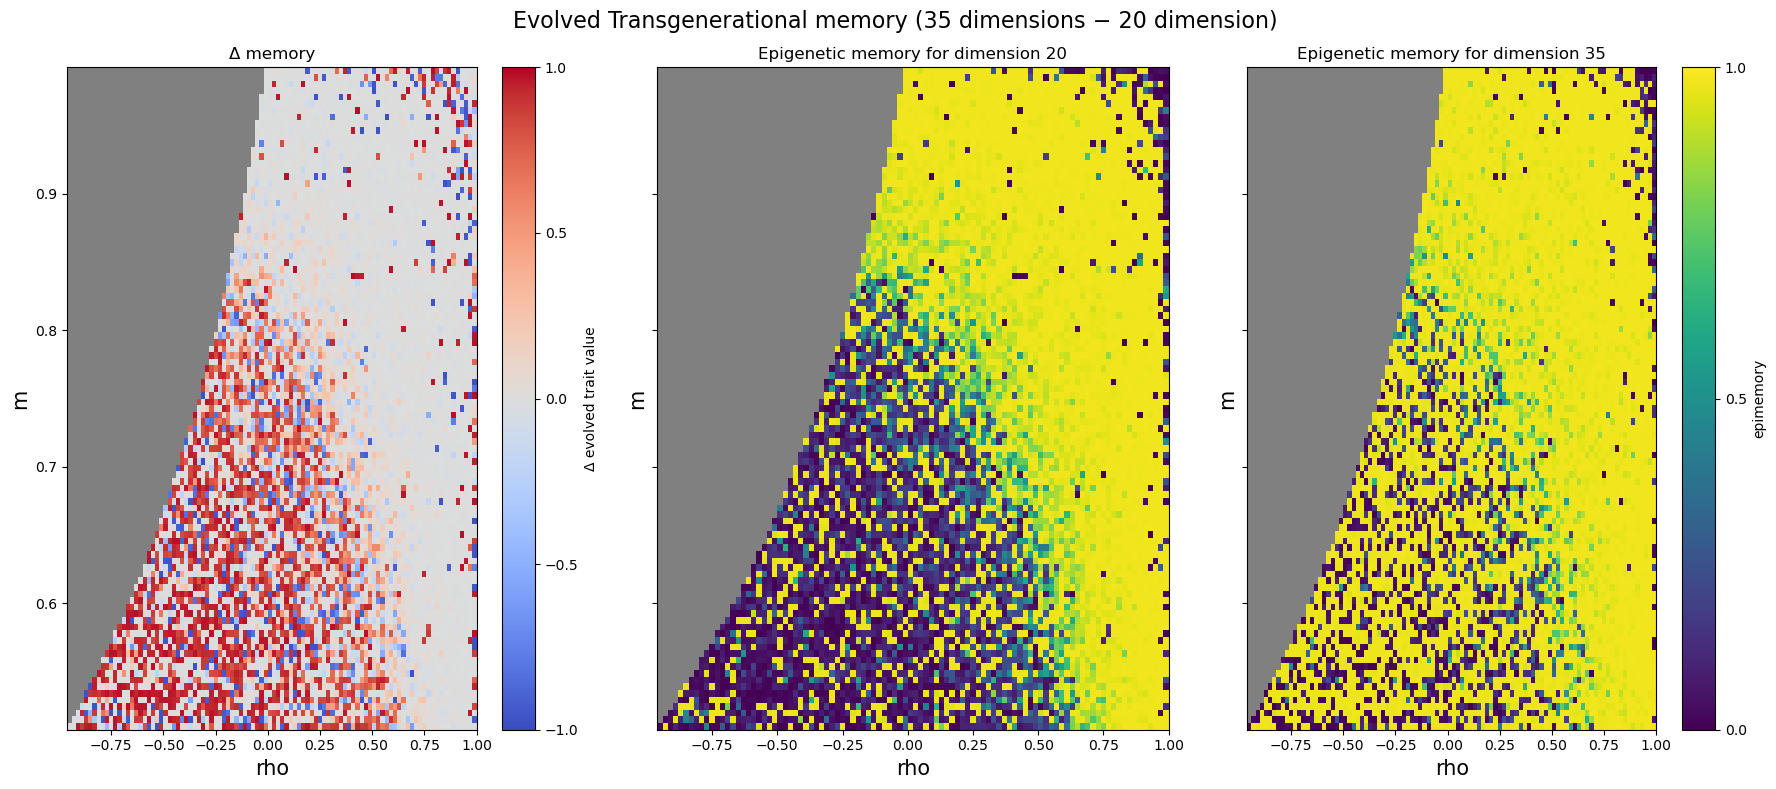

In [ ]:
# Each df has columns: 'm', 'rho', 'epi_mem_p'
dims_base = [1,2,3,5,10,20]
dims_comp = [2, 3, 5, 10, 20, 35]
cmap2 = plt.cm.viridis.copy()
cmap2.set_bad(color='gray')
norm = mcolors.Normalize(vmin=0, vmax=1)
cmap = plt.cm.coolwarm.copy()
cmap.set_bad(color='gray')
norm_diff = mcolors.TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)

for i, j in zip(dims_base,dims_comp):
    base_dim = i
    compare_dim = j
    
    axis_label_size = 15
    fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharex=True, sharey=True)
    fig.suptitle(
        f"Evolved Transgenerational memory ({compare_dim} dimensions − {base_dim} dimension)",
        fontsize=16
    )
    fig.subplots_adjust(top=0.90)

    # LOAD DATA
    epi_base = epi_obj[f"epi_{base_dim}"]
    epi_comp = epi_obj[f"epi_{compare_dim}"]

    pivoted_epi_base = (
        epi_base.pivot_table(index='m', columns='rho', values='epi_mem_p')
        .sort_index().sort_index(axis=1)
    )
    pivoted_epi_comp = (
        epi_comp.pivot_table(index='m', columns='rho', values='epi_mem_p')
        .sort_index().sort_index(axis=1)
    )

    # DIFFERENCES
    delta_mem = pivoted_epi_comp - pivoted_epi_base

    # PLOT 1: Delta
    pcm1 = axes[0].pcolormesh(
        delta_mem.columns, delta_mem.index, delta_mem.values,
        cmap=cmap, norm=norm_diff, shading='auto'
    )
    axes[0].set_title("Δ memory")
    axes[0].set_xlabel("rho", fontsize=axis_label_size)
    axes[0].set_ylabel("m", fontsize=axis_label_size)
    fig.colorbar(pcm1, ax=axes[0], label="Δ evolved trait value", ticks=[-1, -0.5, 0, 0.5, 1])  # Fixed: after pcm1

    # PLOT 2: Base
    pcm_base = axes[1].pcolormesh(
        pivoted_epi_base.columns, pivoted_epi_base.index, pivoted_epi_base.values,
        cmap=cmap2, norm=norm, shading='auto'  # Fixed: consistent norm
    )
    axes[1].set_title(f"Epigenetic memory for dimension {base_dim}")
    axes[1].set_xlabel("rho", fontsize=axis_label_size)
    axes[1].set_ylabel("m", fontsize=axis_label_size)

    # PLOT 3: Compare
    pcm2 = axes[2].pcolormesh(
        pivoted_epi_comp.columns, pivoted_epi_comp.index, pivoted_epi_comp.values,
        cmap=cmap2, norm=norm, shading='auto'  # Fixed: consistent norm
    )
    axes[2].set_title(f"Epigenetic memory for dimension {compare_dim}")
    axes[2].set_xlabel("rho", fontsize=axis_label_size)
    axes[2].set_ylabel("m", fontsize=axis_label_size)
    
    fig.colorbar(pcm2, ax=axes[2], label="epimemory", ticks=[-1, -0.5, 0, 0.5, 1])
    
    plt.tight_layout()
    # plt.savefig(f'output/delta_memory_{compare_dim}dim_minus_{base_dim}dim.png')  # Saves to output/
    plt.show()  # Displays inline

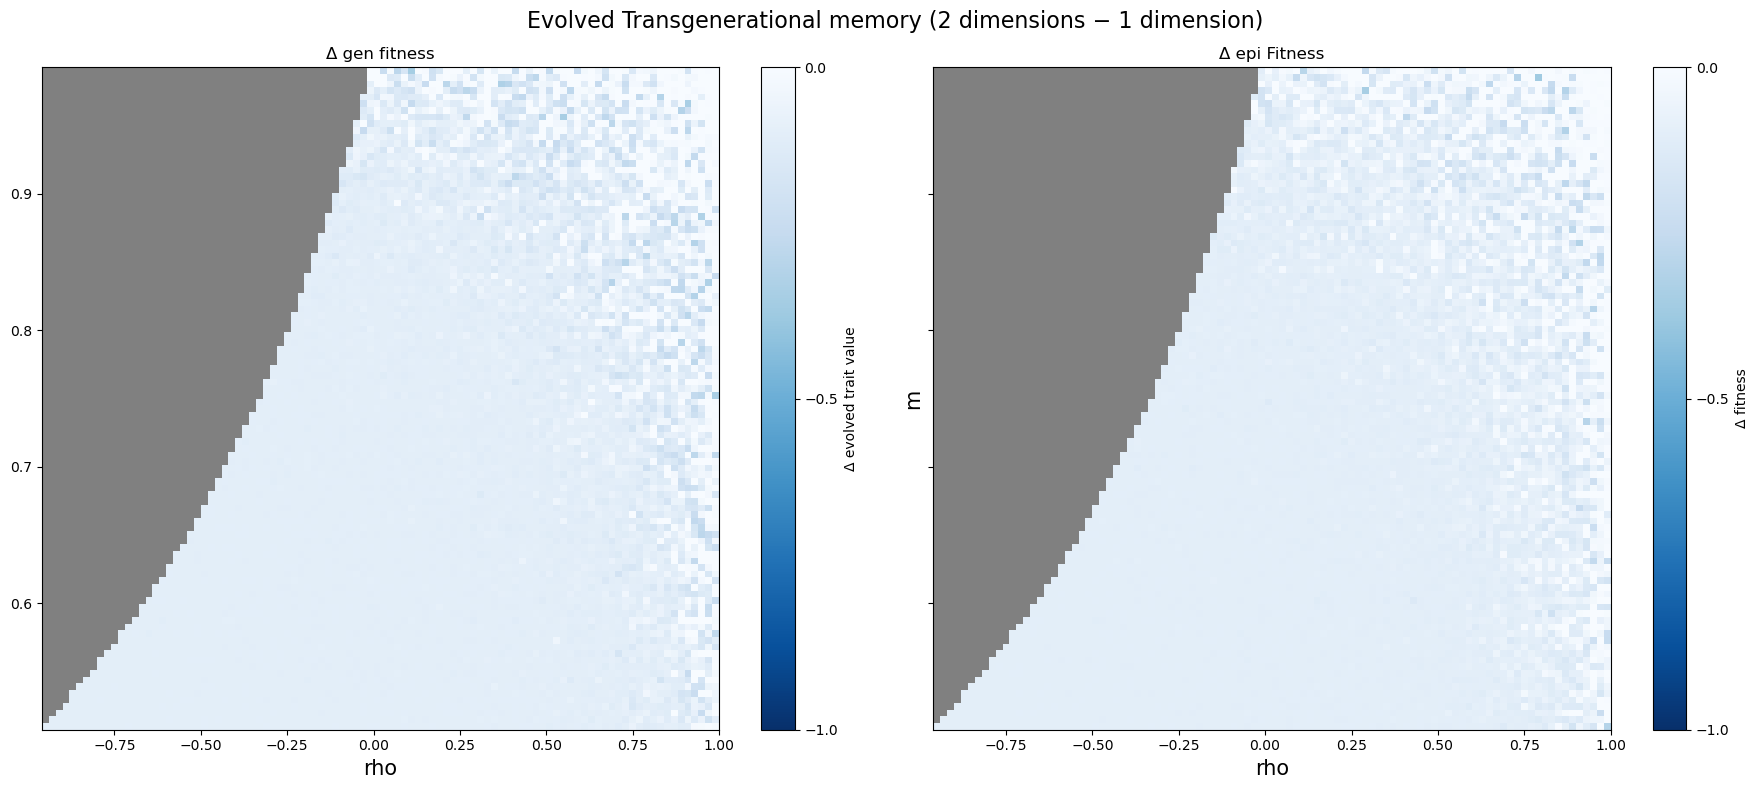

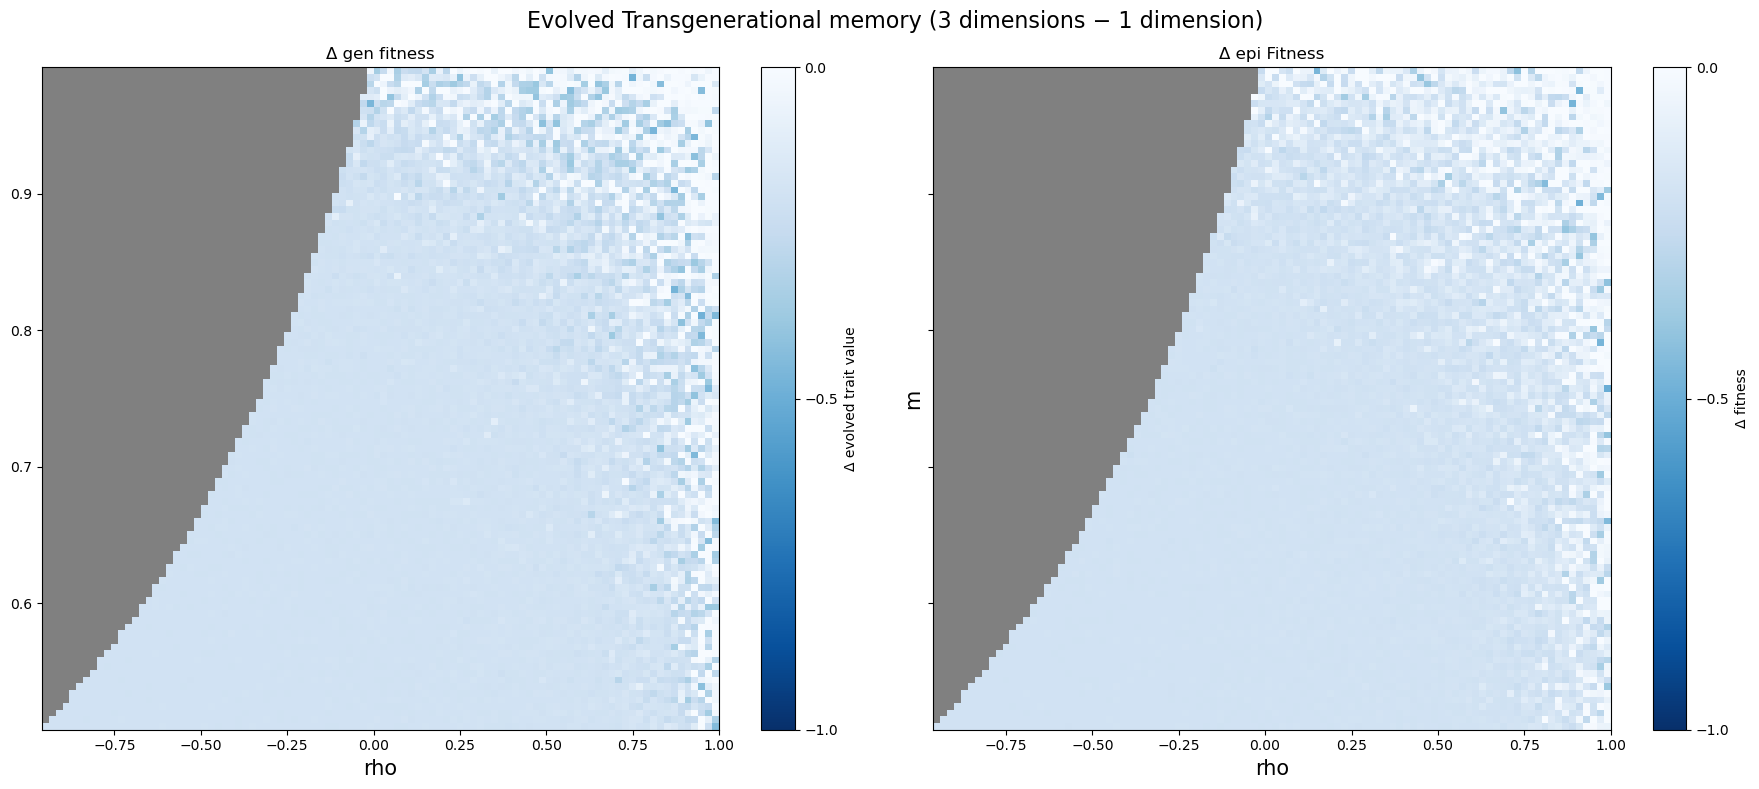

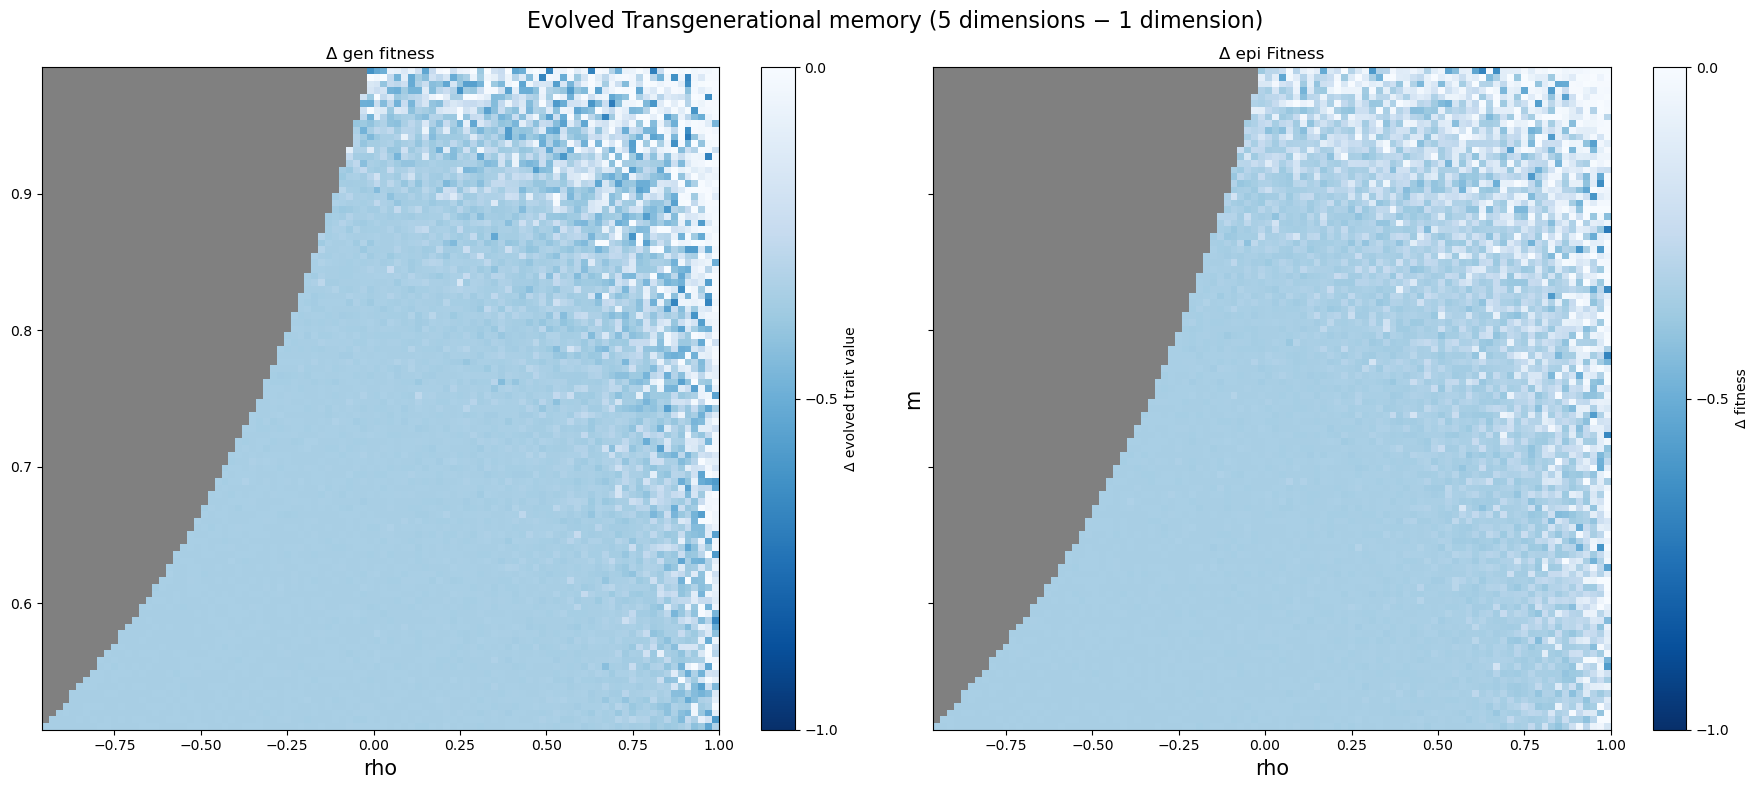

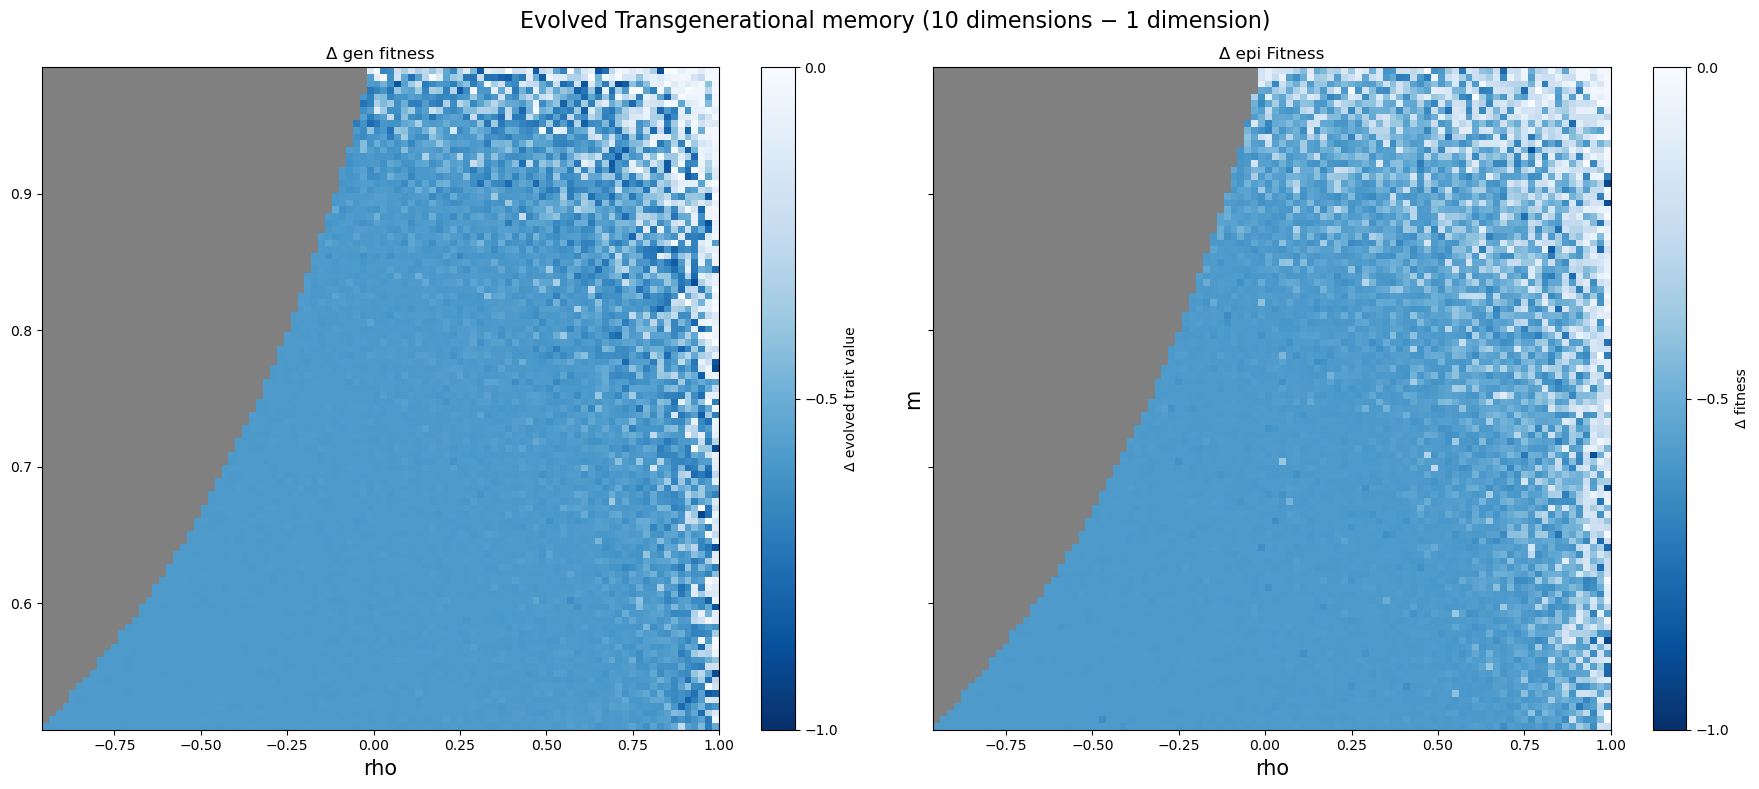

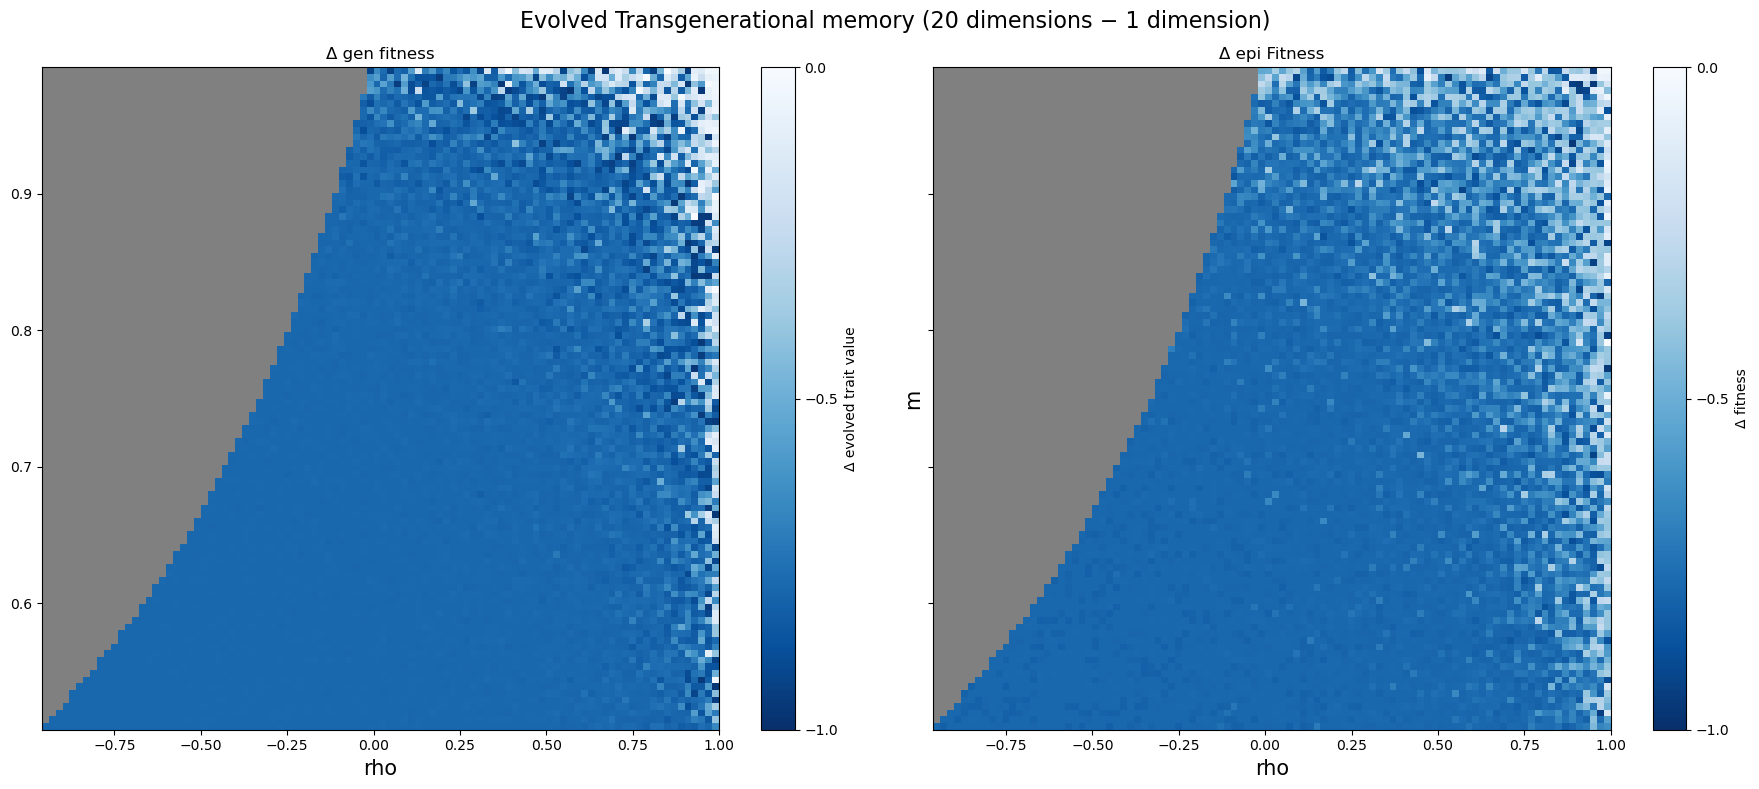

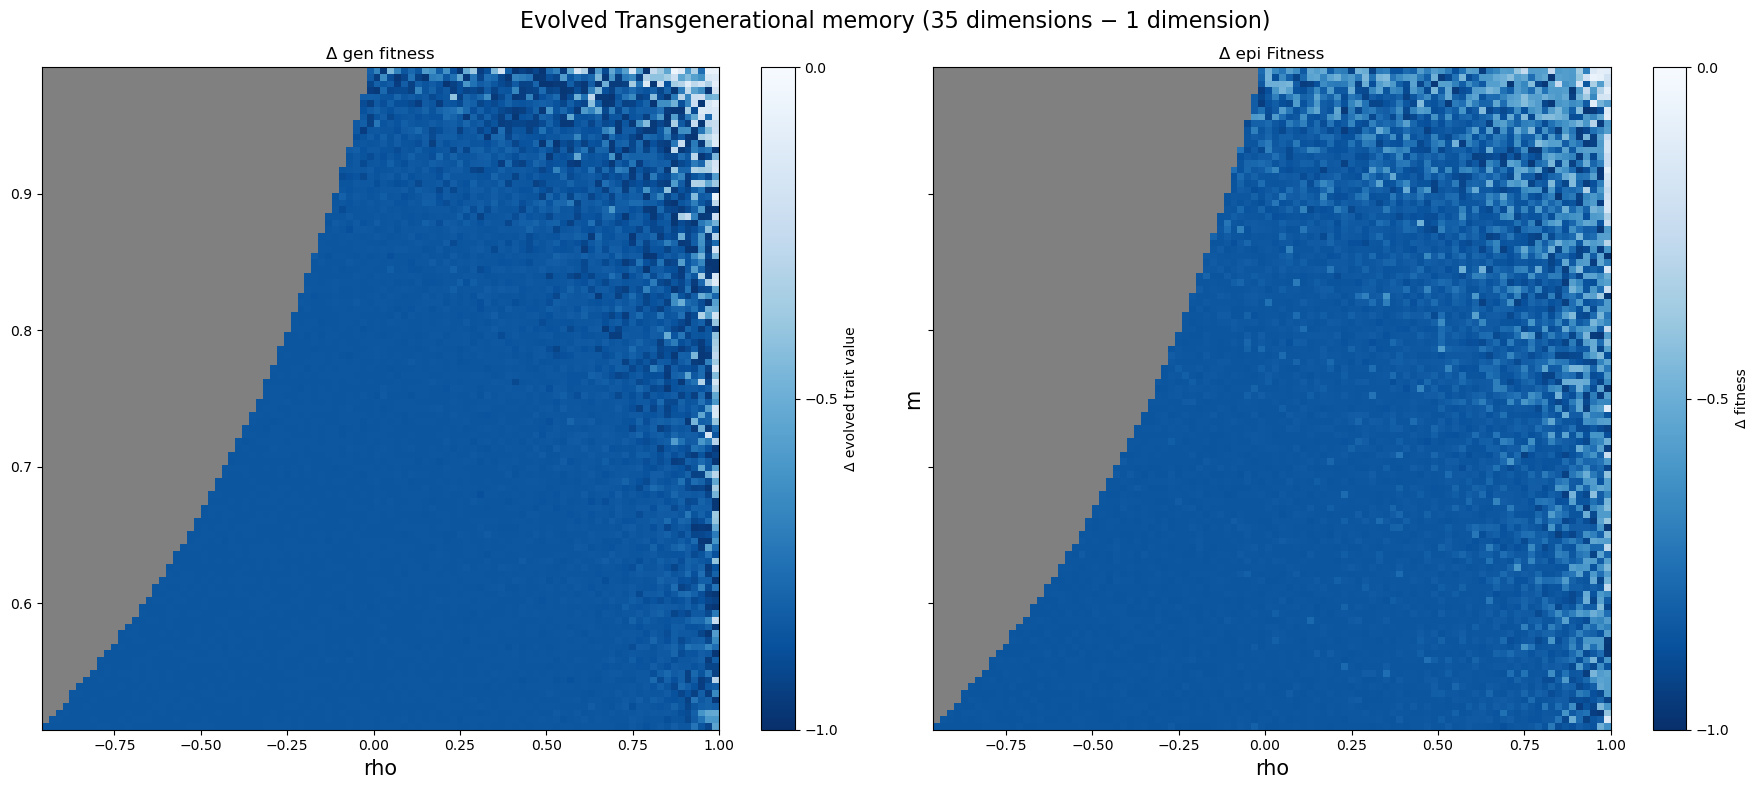

In [ ]:
# ----------
# 0th compariiosn
#---------------
dims_base = [1,2,3,5,10,20]
dims_comp = [2, 3, 5, 10, 20, 35]
for i in dims_comp:
    
    base_dim = 1        # reference
    epi_base = epi_obj[f"epi_{base_dim}"]
    gen_base = onlygen_obj[f"gen_{base_dim}"]
    
    compare_dim = i # <-- change this to 10, 20, etc.
    epi_comp = epi_obj[f"epi_{compare_dim}"].copy()
    gen_comp = onlygen_obj[f"gen_{compare_dim}"].copy()
     
    axis_label_size = 15

    fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharex=True, sharey=True)
    fig.suptitle(
        f"Evolved Transgenerational memory ({compare_dim} dimensions − {base_dim} dimension)",
        fontsize=16
    )
    fig.subplots_adjust(top=0.90)


    cmap1 = plt.cm.Blues_r.copy()
    cmap1.set_bad(color='gray')
    
    # symmetric normalization around 0
    norm_diff = mcolors.TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)
    norm_fitness = mcolors.Normalize(vmin=-1, vmax=0)
    # ---------- LOAD DATA ----------


    pivoted_gen_fitness_base = (
        gen_base
        .pivot_table(index='m', columns='rho', values='fitness')
        .sort_index()
        .sort_index(axis=1)
    )

    pivoted_gen_fitness_comp = (
        gen_comp
        .pivot_table(index='m', columns='rho', values='fitness')
        .sort_index()
        .sort_index(axis=1)
    )

    pivot_fitness_base = (
        epi_base
        .pivot_table(index='m', columns='rho', values='fitness')
        .sort_index()
        .sort_index(axis=1)
    )

    pivot_fitness_comp = (
        epi_comp
        .pivot_table(index='m', columns='rho', values='fitness')
        .sort_index()
        .sort_index(axis=1)
    )

    # ---------- DIFFERENCES ----------
    delta_gen_fitness = pivoted_gen_fitness_comp - pivoted_gen_fitness_base
    delta_fitness = pivot_fitness_comp - pivot_fitness_base

    pcm0 = axes[0].pcolormesh(
        delta_gen_fitness.columns,
        delta_gen_fitness.index,
        delta_gen_fitness.values,
        cmap=cmap1,
        norm=norm_fitness,
        shading='auto'
    )
    axes[0].set_title("Δ gen fitness")
    axes[0].set_xlabel("rho", fontsize=axis_label_size)
    fig.colorbar(
        pcm0,
        ax=axes[0],
        label="Δ evolved trait value",
        ticks=[-1, -0.5, 0, 0.5, 1]
    )
    # ---------- PLOTS ----------
    pcm1 = axes[1].pcolormesh(
        delta_fitness.columns,
        delta_fitness.index,
        delta_fitness.values,
        cmap=cmap1,
        norm=norm_fitness,
        shading='auto'
    )
    axes[1].set_title("Δ epi Fitness")
    axes[1].set_xlabel("rho", fontsize=axis_label_size)
    axes[1].set_ylabel("m", fontsize=axis_label_size)
    # ---------- COLORBAR ----------
    fig.colorbar(
        pcm1,
        ax=axes[1],
        label="Δ fitness",
        ticks=[-1, -0.5, 0, 0.5, 1]
    )

    plt.tight_layout()
    #plt.savefig(f'/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Figures/finegrain_dims/delta_memory{compare_dim}dimensions−{base_dim}dimension.png')
    plt.show()




#### ZONE 2 : Middle

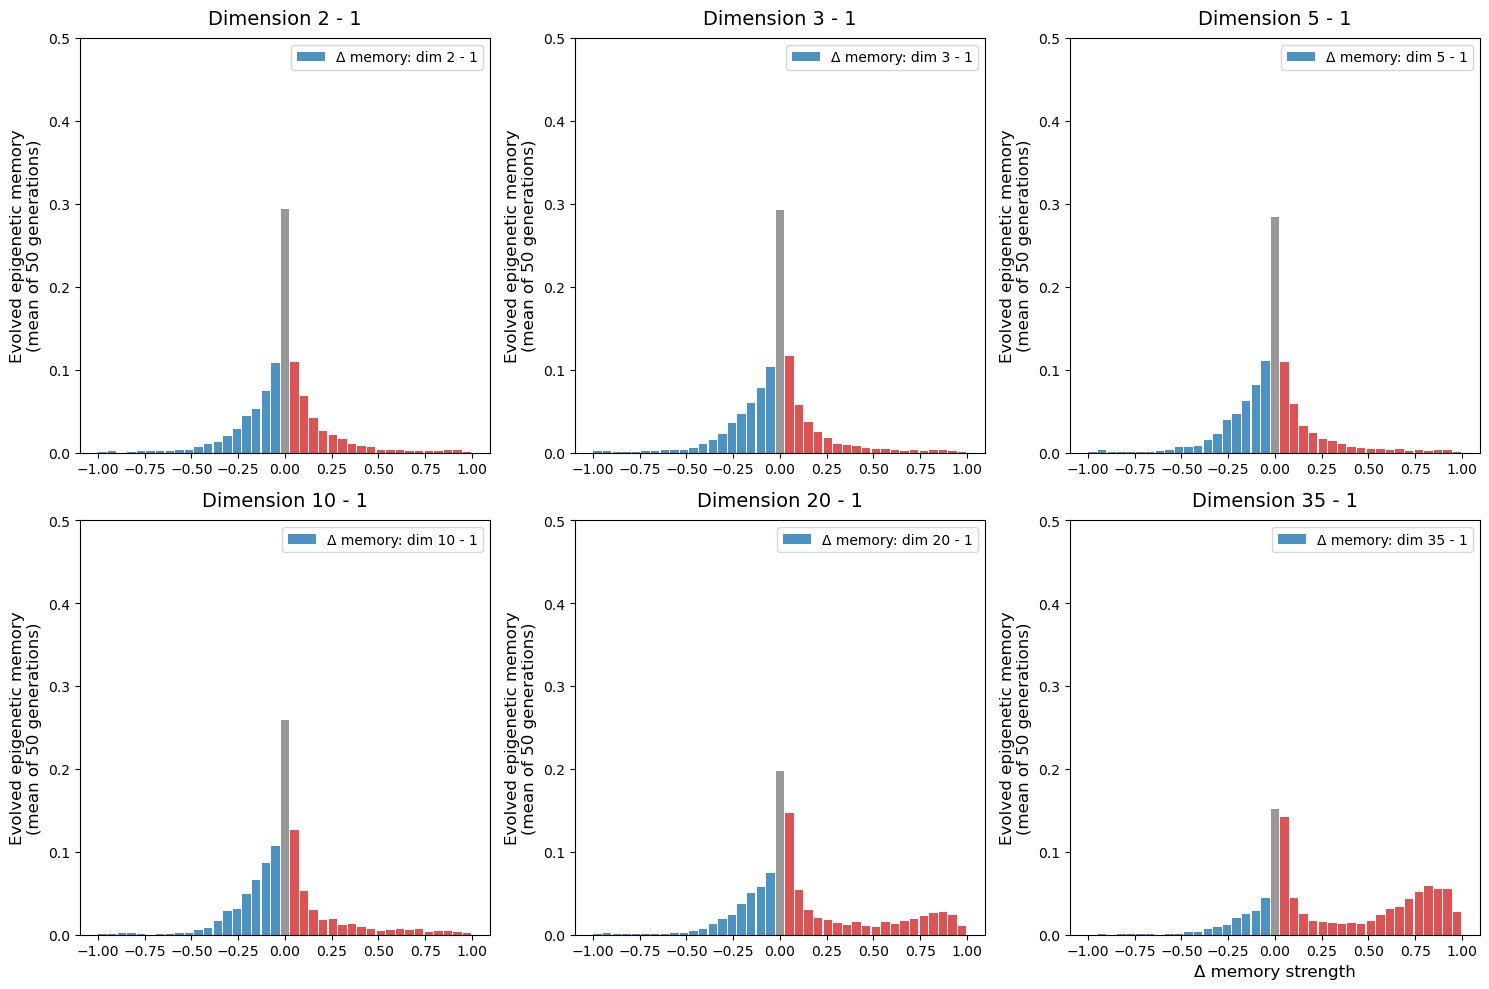

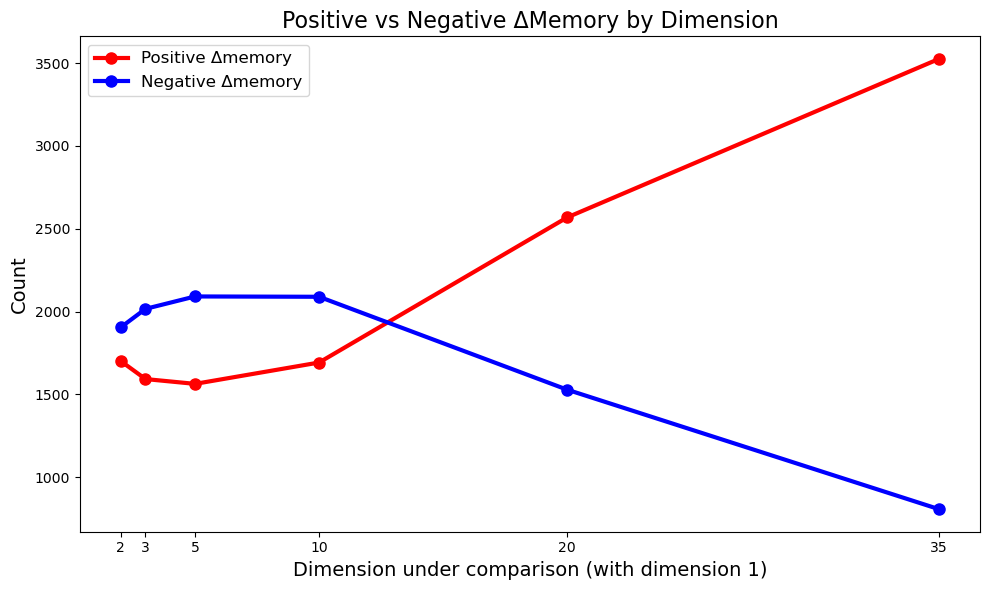

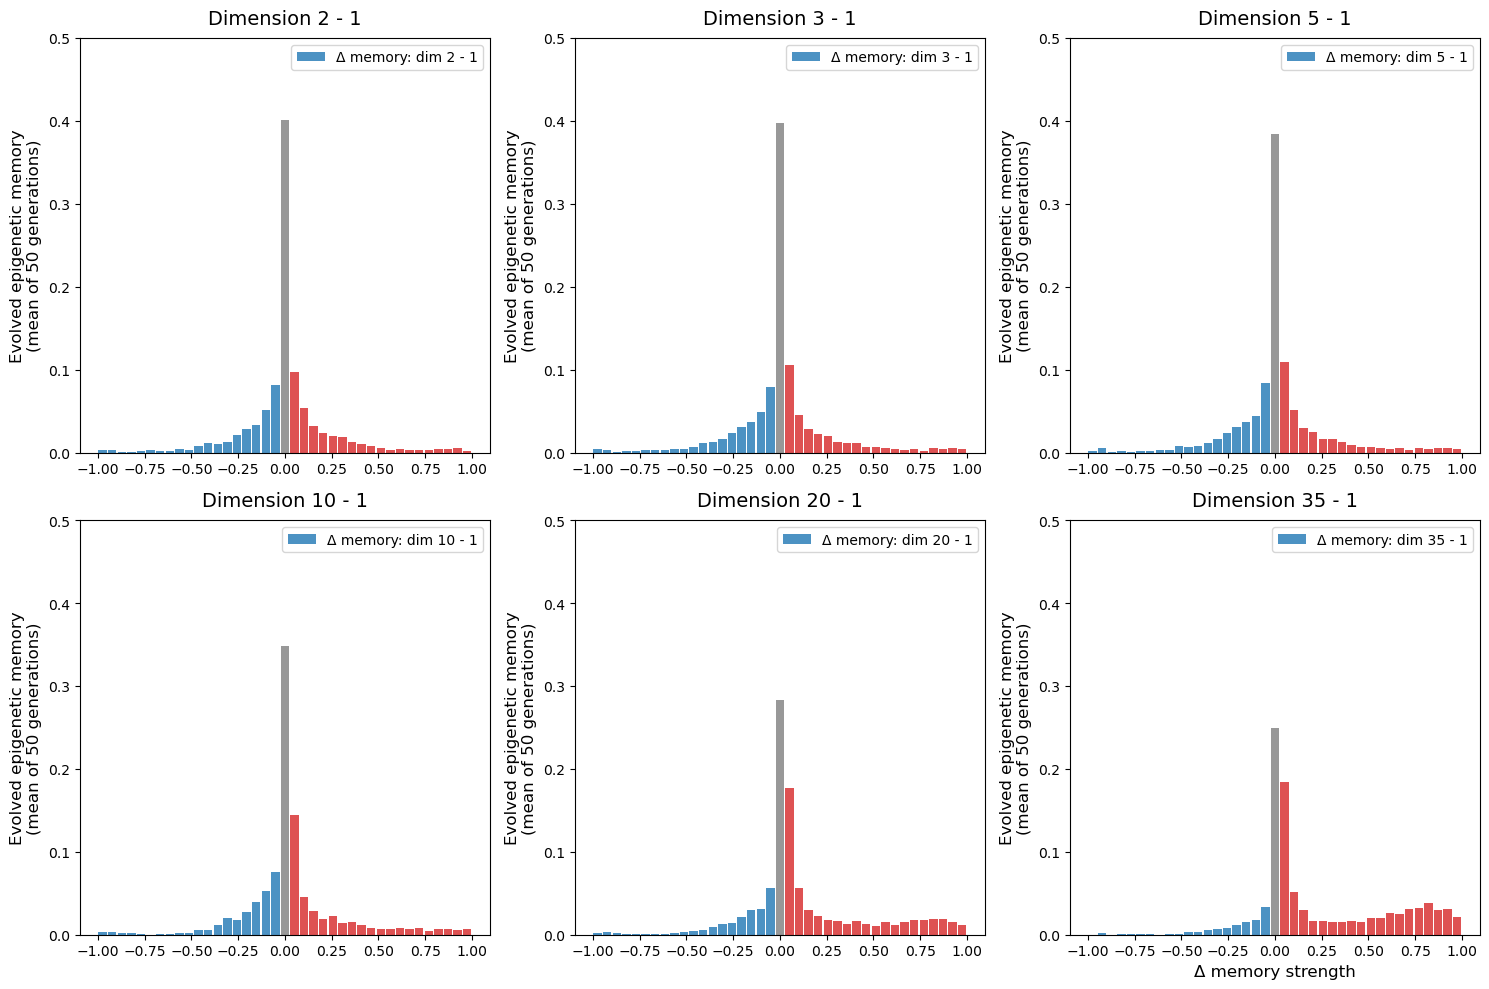

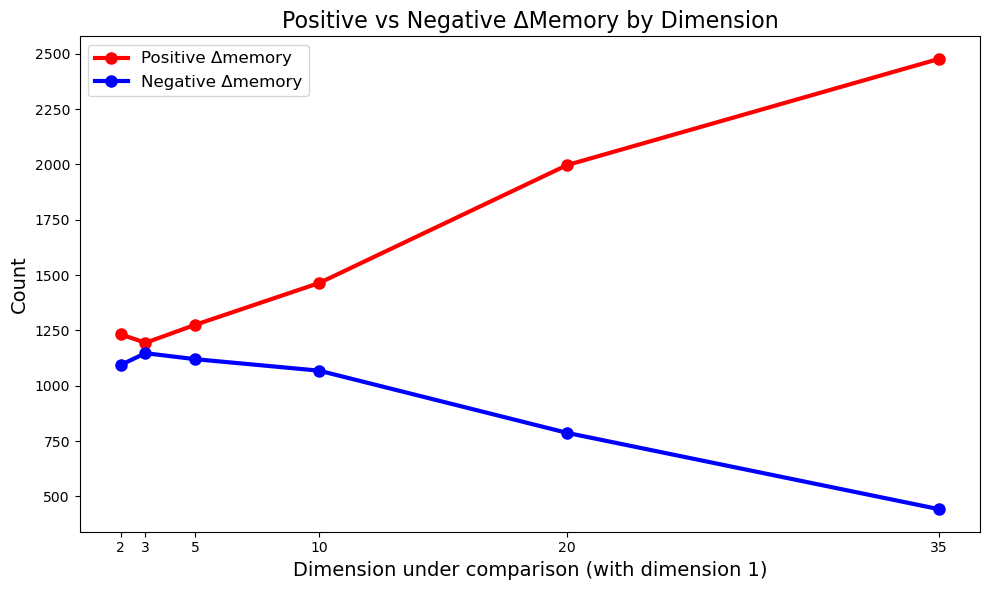

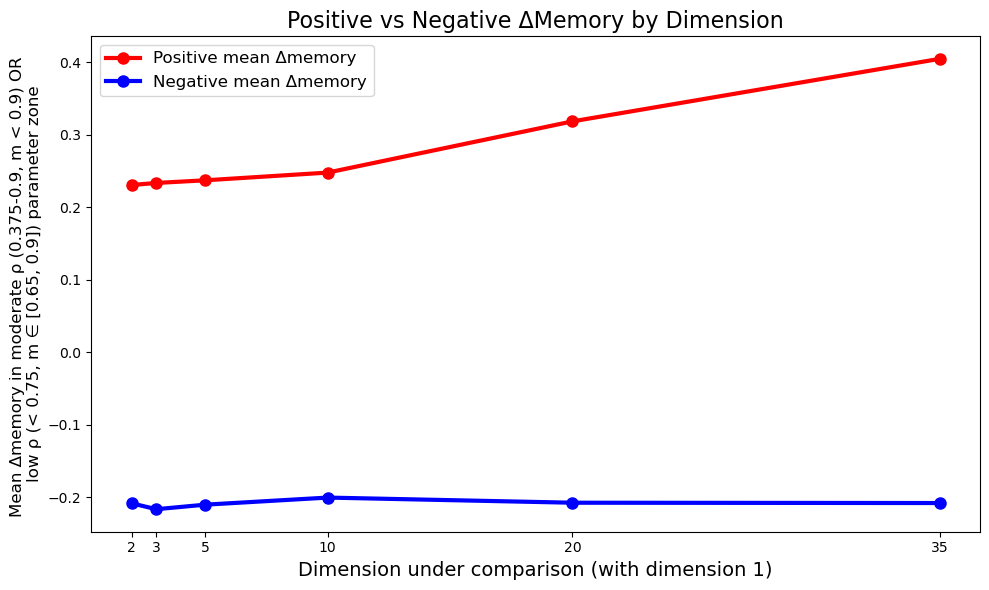

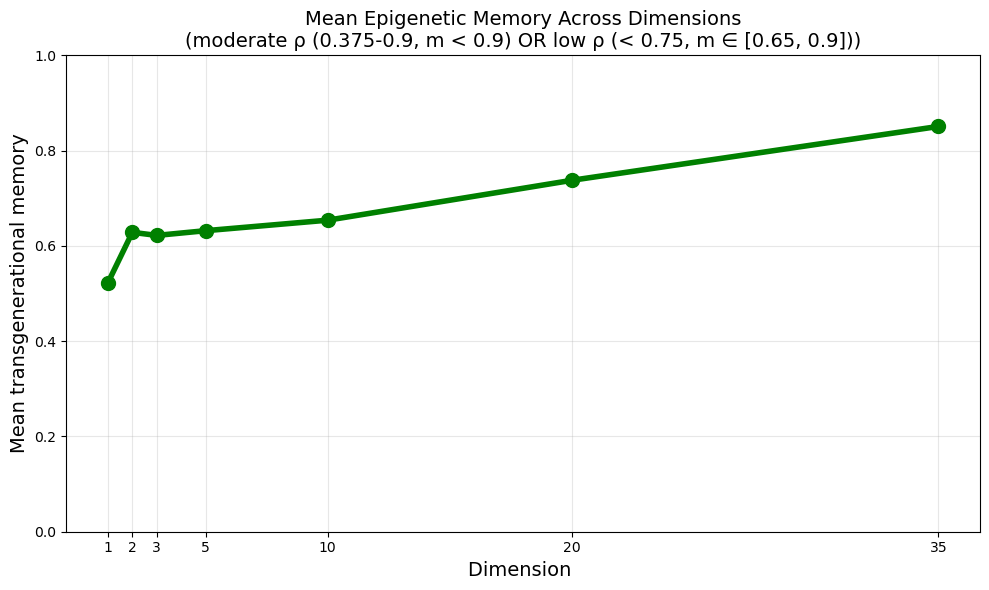

In [ ]:
dim_delta_memory = []
base_dim = 1
compare_dims = [2, 3, 5, 10, 20, 35]

bins = np.linspace(-1, 1, 40)
bin_centers = (bins[:-1] + bins[1:]) / 2  # Proper centers, width ~0.05
width = 0.045  # Match bin width
half = int(len(bins)/2) - 1
bar_colours = np.array(['tab:blue'] * half + ['tab:grey'] + ['tab:red'] * half)


fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()  # Flatten for easy indexing

epi_base = epi_obj[f"epi_{base_dim}"]

for i, compare_dim in enumerate(compare_dims):
    ax = axes[i]
    epi_comp = epi_obj[f"epi_{compare_dim}"].copy()
    epi_comp['delta_memory'] = epi_comp['epi_mem_p'] - epi_base['epi_mem_p']


    condition = ((epi_comp['rho'] < 0.8) & (epi_comp['m'] < 0.9))           

    epi_comp = epi_comp[condition]
    #print(len(epi_comp))
    counts_epi, _ = np.histogram(epi_comp['delta_memory'], bins=bins)
    freq_epi = counts_epi / counts_epi.sum()
 
    ax.bar(bin_centers, freq_epi, width=width, color=bar_colours, alpha=0.8,
           label=f'Δ memory: dim {compare_dim} - {base_dim}')
    ax.set_ylabel("Evolved epigenetic memory\n(mean of 50 generations)", fontsize=12)
    ax.set_ylim(0,0.5)
    ax.set_title(f"Dimension {compare_dim} - {base_dim}", fontsize=14, pad=10)
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.legend(fontsize=10)
    
    n_pos = (epi_comp['delta_memory'] > 0.02564103).sum()
    n_neg = (epi_comp['delta_memory'] < -0.02564103).sum()
    dim_delta_memory.append([compare_dim , n_pos, n_neg])

axes[-1].set_xlabel("Δ memory strength", fontsize=12)
plt.tight_layout()
plt.show()

# Extract all three columns properly
compare_dim = np.array([d[0] for d in dim_delta_memory])
n_pos = np.array([d[1] for d in dim_delta_memory])
n_neg = np.array([d[2] for d in dim_delta_memory])
#print(dim_delta_memory)

# Complete figure with both positive/negative + proper axes
plt.figure(figsize=(10, 6))
plt.plot(compare_dim, n_pos, 'ro-', linewidth=3, markersize=8, label='Positive Δmemory')
plt.plot(compare_dim, n_neg, 'bo-', linewidth=3, markersize=8, label='Negative Δmemory')
plt.xlabel('Dimension under comparison (with dimension 1)', fontsize=14)
plt.ylabel('Count', fontsize=14)
#plt.ylim(0,600)
plt.title('Positive vs Negative ΔMemory by Dimension', fontsize=16)
plt.legend(fontsize=12)
plt.xticks(compare_dim)  # Show all dimension ticks
plt.tight_layout()
plt.show()



###########  Middle Strip #############

dim_delta_memory = []
dim_mean_memory = []
dim_mean_delta_pos_neg_memory=[]
base_dim = 1
compare_dims = [2, 3, 5, 10, 20, 35]

bins = np.linspace(-1, 1, 40)
bin_centers = (bins[:-1] + bins[1:]) / 2  # Proper centers, width ~0.05
width = 0.045  # Match bin width
half = int(len(bins)/2) - 1
bar_colours = np.array(['tab:blue'] * half + ['tab:grey'] + ['tab:red'] * half)


fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()  # Flatten for easy indexing

epi_base = epi_obj[f"epi_{base_dim}"]
dim_mean_memory.append([1, epi_base['epi_mem_p'].mean()])

for i, compare_dim in enumerate(compare_dims):
    ax = axes[i]
    epi_comp = epi_obj[f"epi_{compare_dim}"].copy()
    epi_comp['delta_memory'] = epi_comp['epi_mem_p'] - epi_base['epi_mem_p']

    #print(len(epi_comp['delta_memory']))
    condition = (((epi_comp['rho'] > 0.375) & (epi_comp['rho'] < 0.9) &  (epi_comp['m'] < 0.9)) |
                ( (epi_comp['rho']) < 0.75) & ((epi_comp['m']) > 0.65) &  ((epi_comp['m']) < 0.9) )                            
    
    epi_comp = epi_comp[condition]
    #print(len(epi_comp))
    counts_epi, _ = np.histogram(epi_comp['delta_memory'], bins=bins)
    freq_epi = counts_epi / counts_epi.sum()
 
    ax.bar(bin_centers, freq_epi, width=width, color=bar_colours, alpha=0.8,
           label=f'Δ memory: dim {compare_dim} - {base_dim}')
    ax.set_ylabel("Evolved epigenetic memory\n(mean of 50 generations)", fontsize=12)
    ax.set_ylim(0,0.5)
    ax.set_title(f"Dimension {compare_dim} - {base_dim}", fontsize=14, pad=10)
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.legend(fontsize=10)
    n_pos = (epi_comp['delta_memory'] > 0.02564103).sum()
    n_neg = (epi_comp['delta_memory'] < -0.02564103).sum()
    
    pos_mask = epi_comp['delta_memory'] > 0.02564103
    neg_mask = epi_comp['delta_memory'] < -0.02564103

    mean_pos = epi_comp.loc[pos_mask, 'delta_memory'].mean() # mean ememory in pos differentce envs
    mean_neg = epi_comp.loc[neg_mask, 'delta_memory'].mean() # mean ememory in neg differentce envs
    
    dim_mean_memory.append([compare_dim, epi_comp['epi_mem_p'].mean()])
    
    dim_delta_memory.append([compare_dim , n_pos, n_neg])
    dim_mean_delta_pos_neg_memory.append([compare_dim , mean_pos, mean_neg])
    
axes[-1].set_xlabel("Δ memory strength", fontsize=12)
plt.tight_layout()
plt.show()

# Extract all three columns properly
#print(dim_delta_memory)
compare_dim = np.array([d[0] for d in dim_delta_memory])
n_pos = np.array([d[1] for d in dim_delta_memory])
n_neg = np.array([d[2] for d in dim_delta_memory])

# Complete figure with both positive/negative + proper axes
plt.figure(figsize=(10, 6))
plt.plot(compare_dim, n_pos, 'ro-', linewidth=3, markersize=8, label='Positive Δmemory')
plt.plot(compare_dim, n_neg, 'bo-', linewidth=3, markersize=8, label='Negative Δmemory')
plt.xlabel('Dimension under comparison (with dimension 1)', fontsize=14)
plt.ylabel('Count', fontsize=14)
#plt.ylim(0,600)
plt.title('Positive vs Negative ΔMemory by Dimension', fontsize=16)
plt.legend(fontsize=12)
plt.xticks(compare_dim)  # Show all dimension ticks
plt.tight_layout()
plt.show()

# Extract all three columns properly
#print(dim_delta_memory)
compare_dim = np.array([d[0] for d in dim_mean_delta_pos_neg_memory])
mean_pos = np.array([d[1] for d in dim_mean_delta_pos_neg_memory])
mean_neg = np.array([d[2] for d in dim_mean_delta_pos_neg_memory])

# Complete figure with both positive/negative + proper axes
plt.figure(figsize=(10, 6))
plt.plot(compare_dim, mean_pos, 'ro-', linewidth=3, markersize=8, label='Positive mean Δmemory')
plt.plot(compare_dim, mean_neg, 'bo-', linewidth=3, markersize=8, label='Negative mean Δmemory')
plt.xlabel('Dimension under comparison (with dimension 1)', fontsize=14)
plt.ylabel('Mean Δmemory in moderate ρ (0.375-0.9, m < 0.9) OR \nlow ρ (< 0.75, m ∈ [0.65, 0.9]) parameter zone', fontsize=12)
#plt.ylim(0,600)
plt.title('Positive vs Negative ΔMemory by Dimension', fontsize=16)
plt.legend(fontsize=12)
plt.xticks(compare_dim)  # Show all dimension ticks
plt.tight_layout()
plt.show()


compare_dim_mean = np.array([d[0] for d in dim_mean_memory])
mean_epi_mem_p = np.array([d[1] for d in dim_mean_memory])

plt.figure(figsize=(10, 6))
plt.plot(compare_dim_mean, mean_epi_mem_p, 'go-', linewidth=4, markersize=10)
plt.xlabel('Dimension ', fontsize=14)
plt.ylabel('Mean transgenerational memory', fontsize=14)
plt.title('Mean Epigenetic Memory Across Dimensions\n(moderate ρ (0.375-0.9, m < 0.9) OR low ρ (< 0.75, m ∈ [0.65, 0.9]))', fontsize=14)
plt.grid(True, alpha=0.3)
plt.ylim(0,1)
plt.xticks(np.concatenate([[1], compare_dim]))
plt.tight_layout()
plt.show()

In [ ]:
compare_dim

array([ 2,  3,  5, 10, 20, 35])

#### ZONE 1 : Right corner

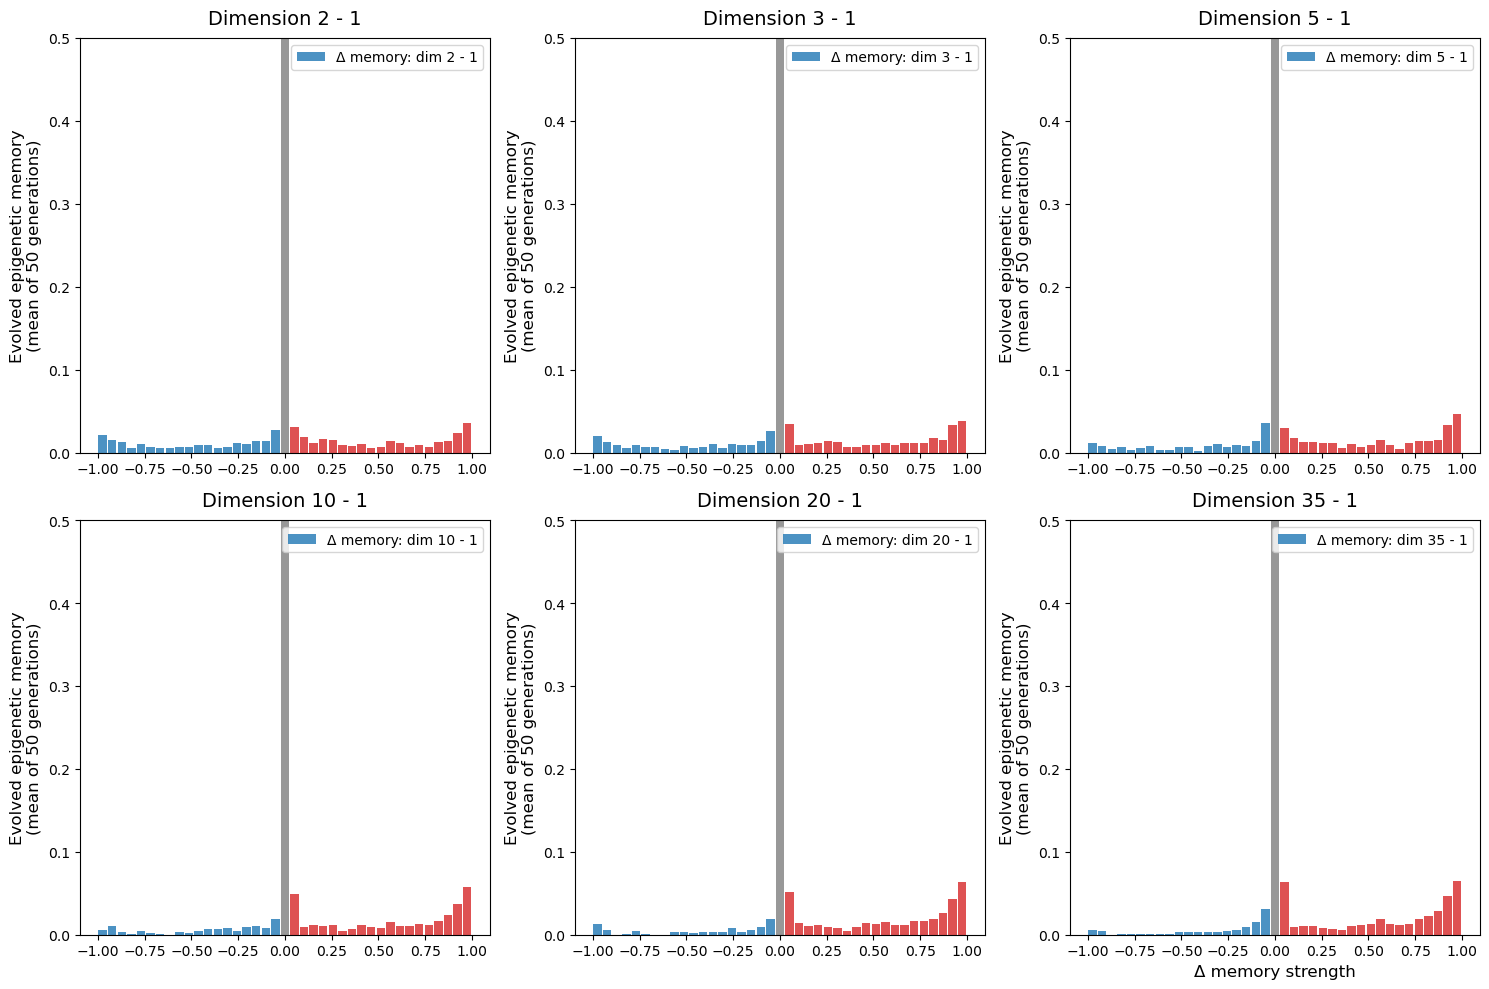

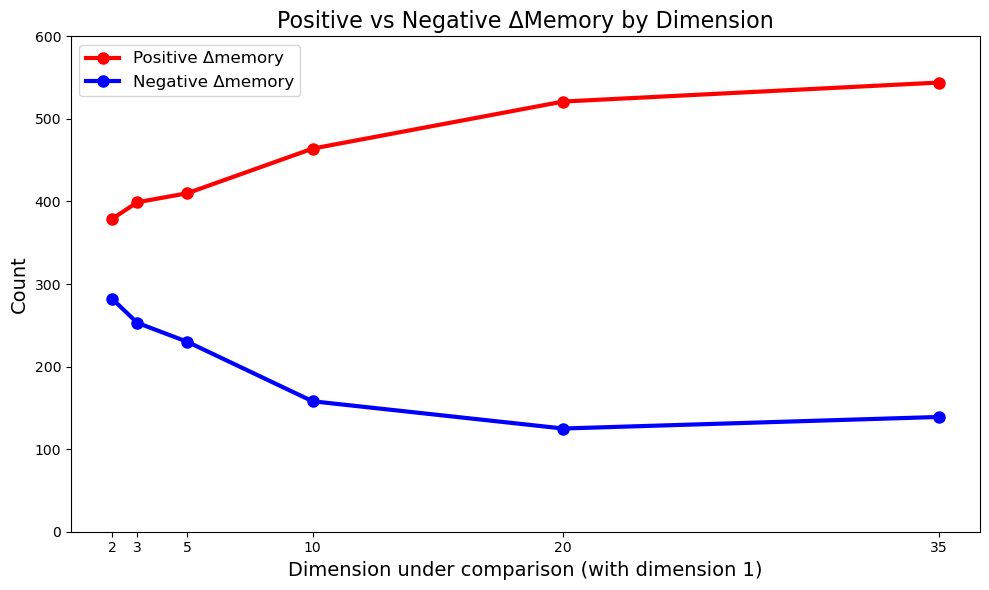

In [ ]:
dim_delta_memory = []
base_dim = 1
compare_dims = [2, 3, 5, 10, 20, 35]

bins = np.linspace(-1, 1, 40)
bin_centers = (bins[:-1] + bins[1:]) / 2  # Proper centers, width ~0.05
width = 0.045  # Match bin width
half = int(len(bins)/2) - 1
bar_colours = np.array(['tab:blue'] * half + ['tab:grey'] + ['tab:red'] * half)


fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()  # Flatten for easy indexing

epi_base = epi_obj[f"epi_{base_dim}"]

for i, compare_dim in enumerate(compare_dims):
    ax = axes[i]
    epi_comp = epi_obj[f"epi_{compare_dim}"].copy()
    epi_comp['delta_memory'] = epi_comp['epi_mem_p'] - epi_base['epi_mem_p']
    # Optional condition (uncomment/adjust as needed)
    condition = (
         ((epi_comp['rho'] > 0.9) & (epi_comp['m'] > 0.5)) |             
         ((epi_comp['rho'] > -0.25) & (epi_comp['m'] > 0.9) ))             #OR very high environmental autocorrelation (ρ > 0.9 with m > 0.5)
                                                                            # High meant time spent (m > 0.9, mean time spent) regardless of environmental autocorrelation, 
    # )
    epi_comp = epi_comp[condition]

    counts_epi, _ = np.histogram(epi_comp['delta_memory'], bins=bins)
    freq_epi = counts_epi / counts_epi.sum()
 
    ax.bar(bin_centers, freq_epi, width=width, color=bar_colours, alpha=0.8,
           label=f'Δ memory: dim {compare_dim} - {base_dim}')
    ax.set_ylabel("Evolved epigenetic memory\n(mean of 50 generations)", fontsize=12)
    ax.set_ylim(0,0.5)
    ax.set_title(f"Dimension {compare_dim} - {base_dim}", fontsize=14, pad=10)
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.legend(fontsize=10)
    
    n_pos = (epi_comp['delta_memory'] > 0.02564103).sum()
    n_neg = (epi_comp['delta_memory'] < -0.02564103).sum()
    dim_delta_memory.append([compare_dim , n_pos, n_neg])

axes[-1].set_xlabel("Δ memory strength", fontsize=12)
plt.tight_layout()
plt.show()

# Extract all three columns properly
compare_dim = np.array([d[0] for d in dim_delta_memory])
n_pos = np.array([d[1] for d in dim_delta_memory])
n_neg = np.array([d[2] for d in dim_delta_memory])

# Complete figure with both positive/negative + proper axes
plt.figure(figsize=(10, 6))
plt.plot(compare_dim, n_pos, 'ro-', linewidth=3, markersize=8, label='Positive Δmemory')
plt.plot(compare_dim, n_neg, 'bo-', linewidth=3, markersize=8, label='Negative Δmemory')
plt.xlabel('Dimension under comparison (with dimension 1)', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.ylim(0,600)
plt.title('Positive vs Negative ΔMemory by Dimension', fontsize=16)
plt.legend(fontsize=12)
plt.xticks(compare_dim)  # Show all dimension ticks
plt.tight_layout()
plt.show()

#### Fitness under transgenerational memory: does it increase or decrease fitness with increasing dimensions

In [ ]:
min_abs

np.float64(4.972914424669775e-06)

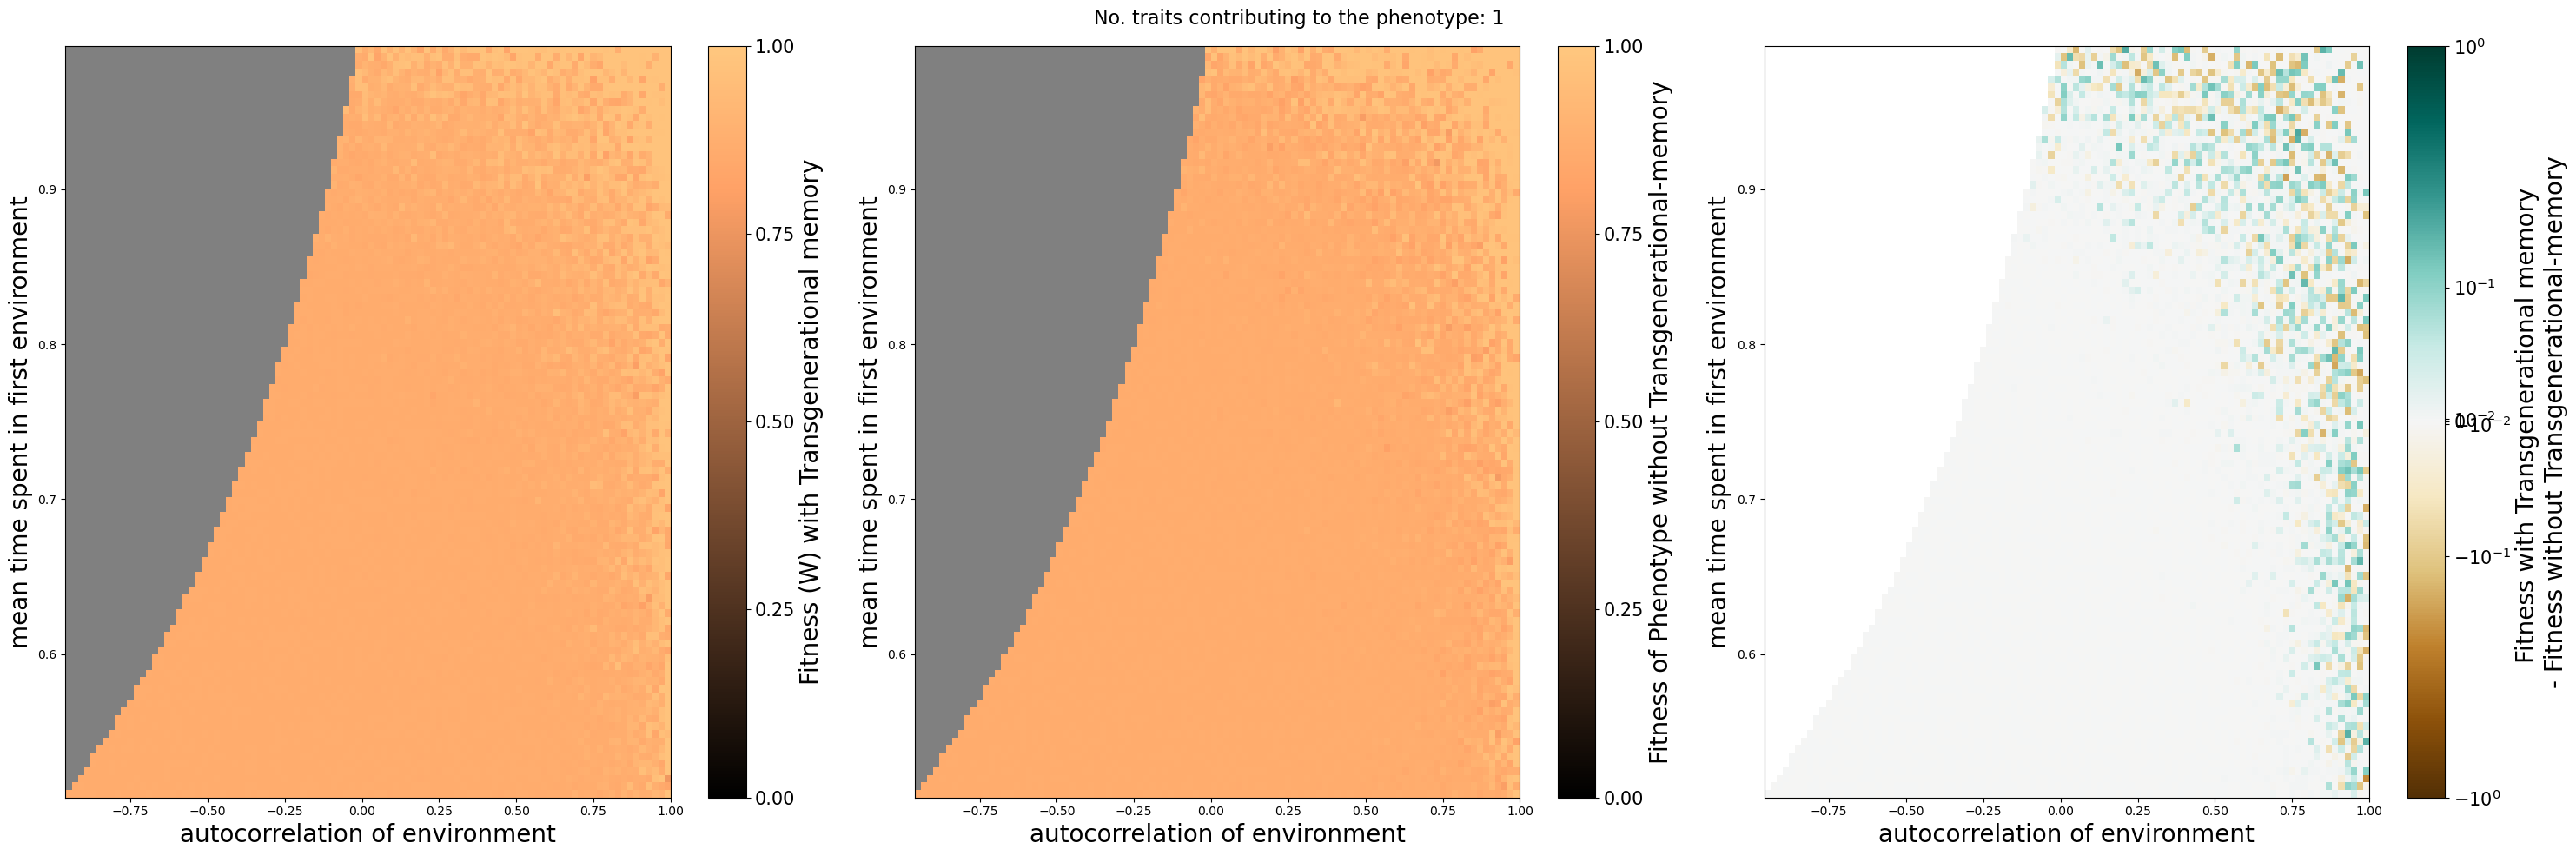

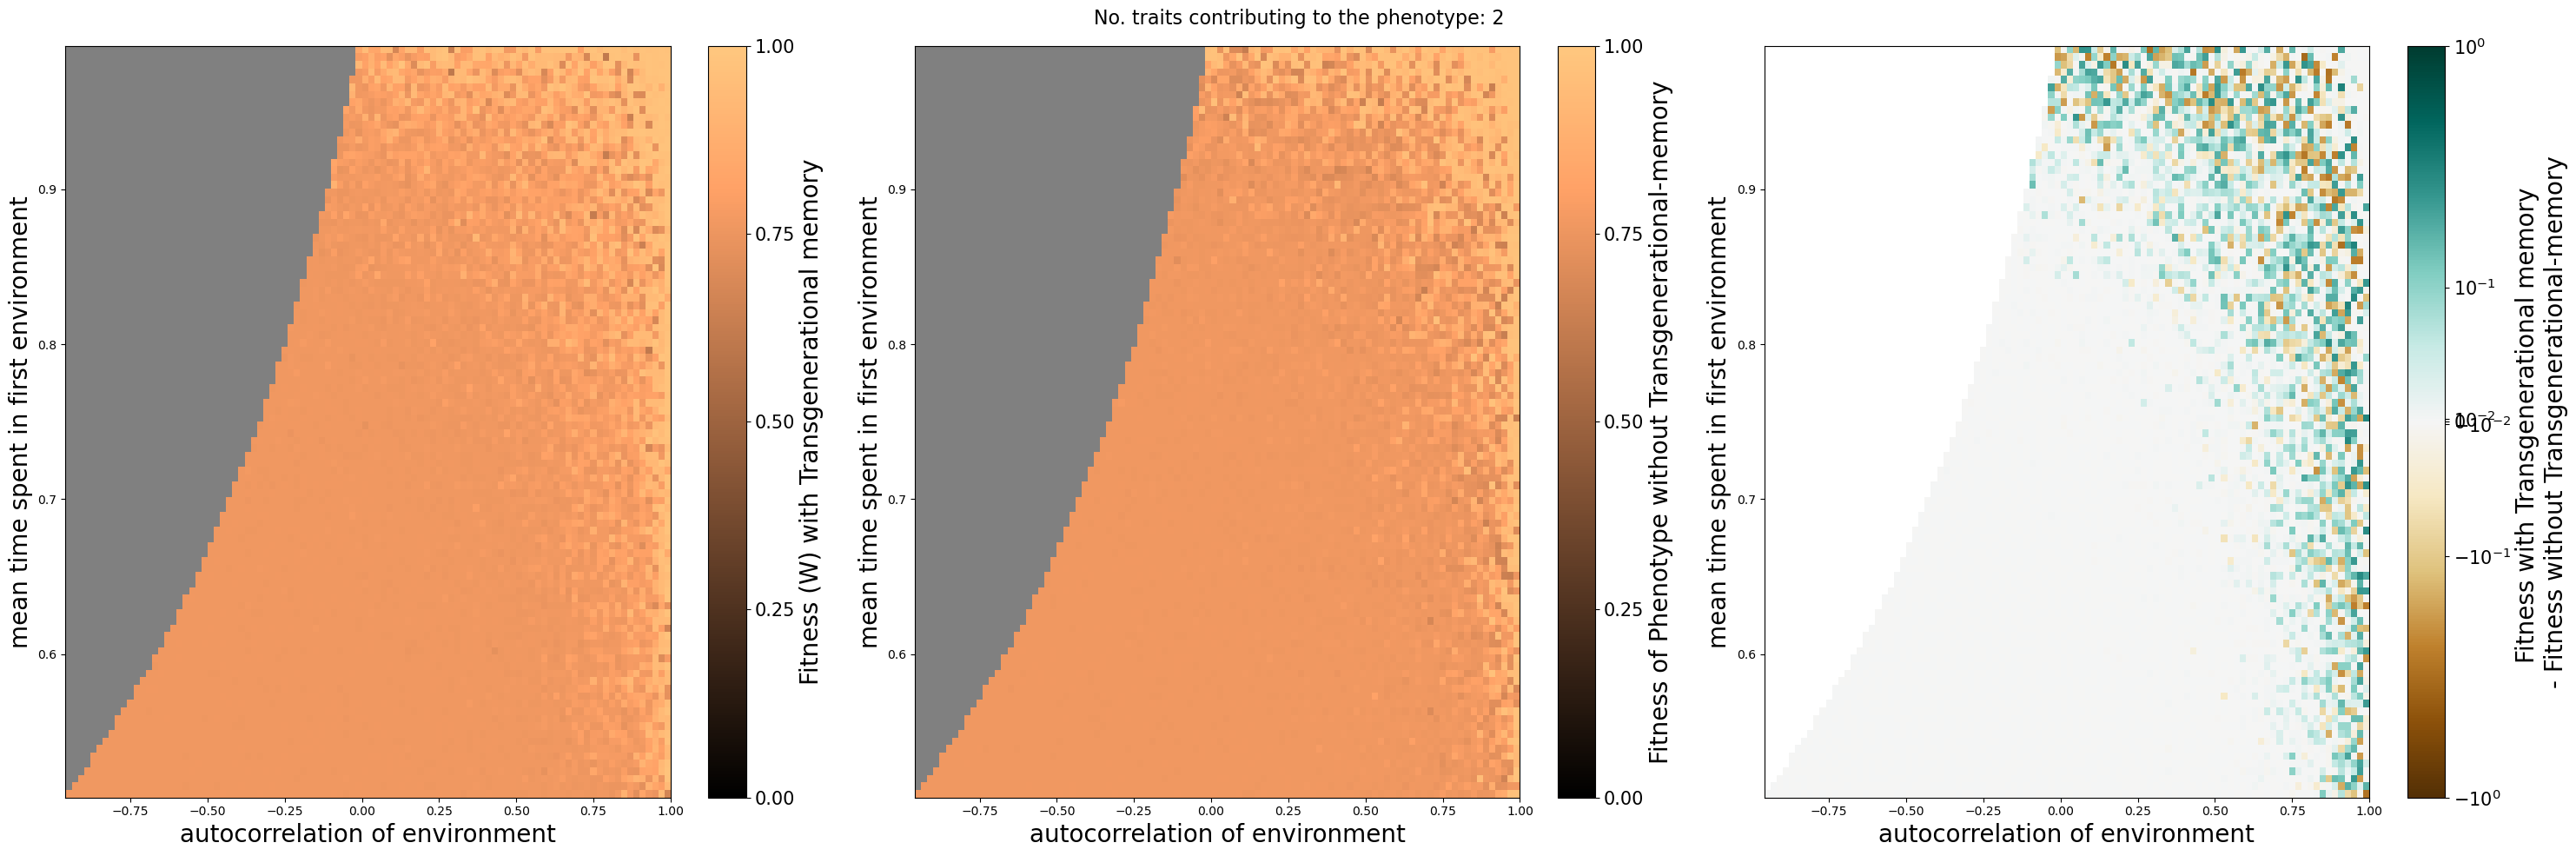

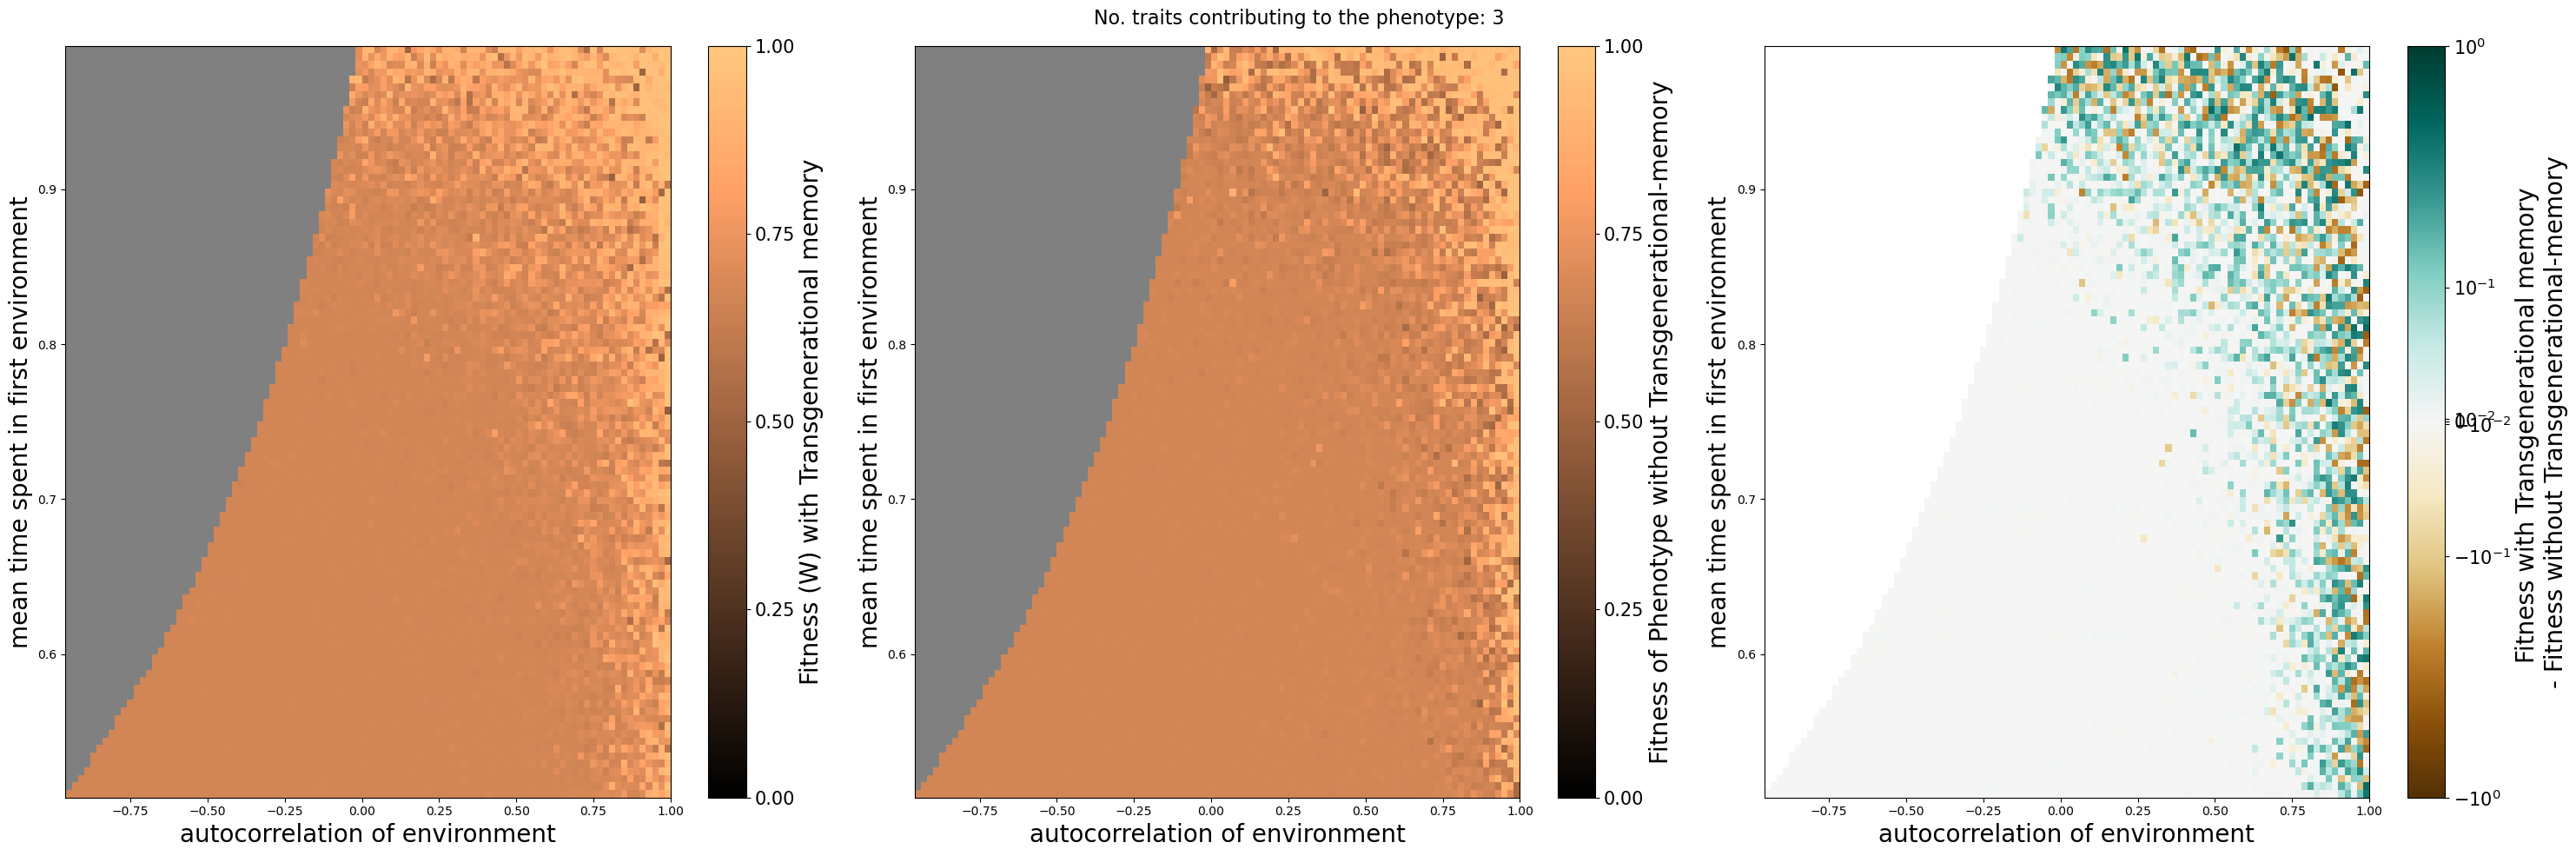

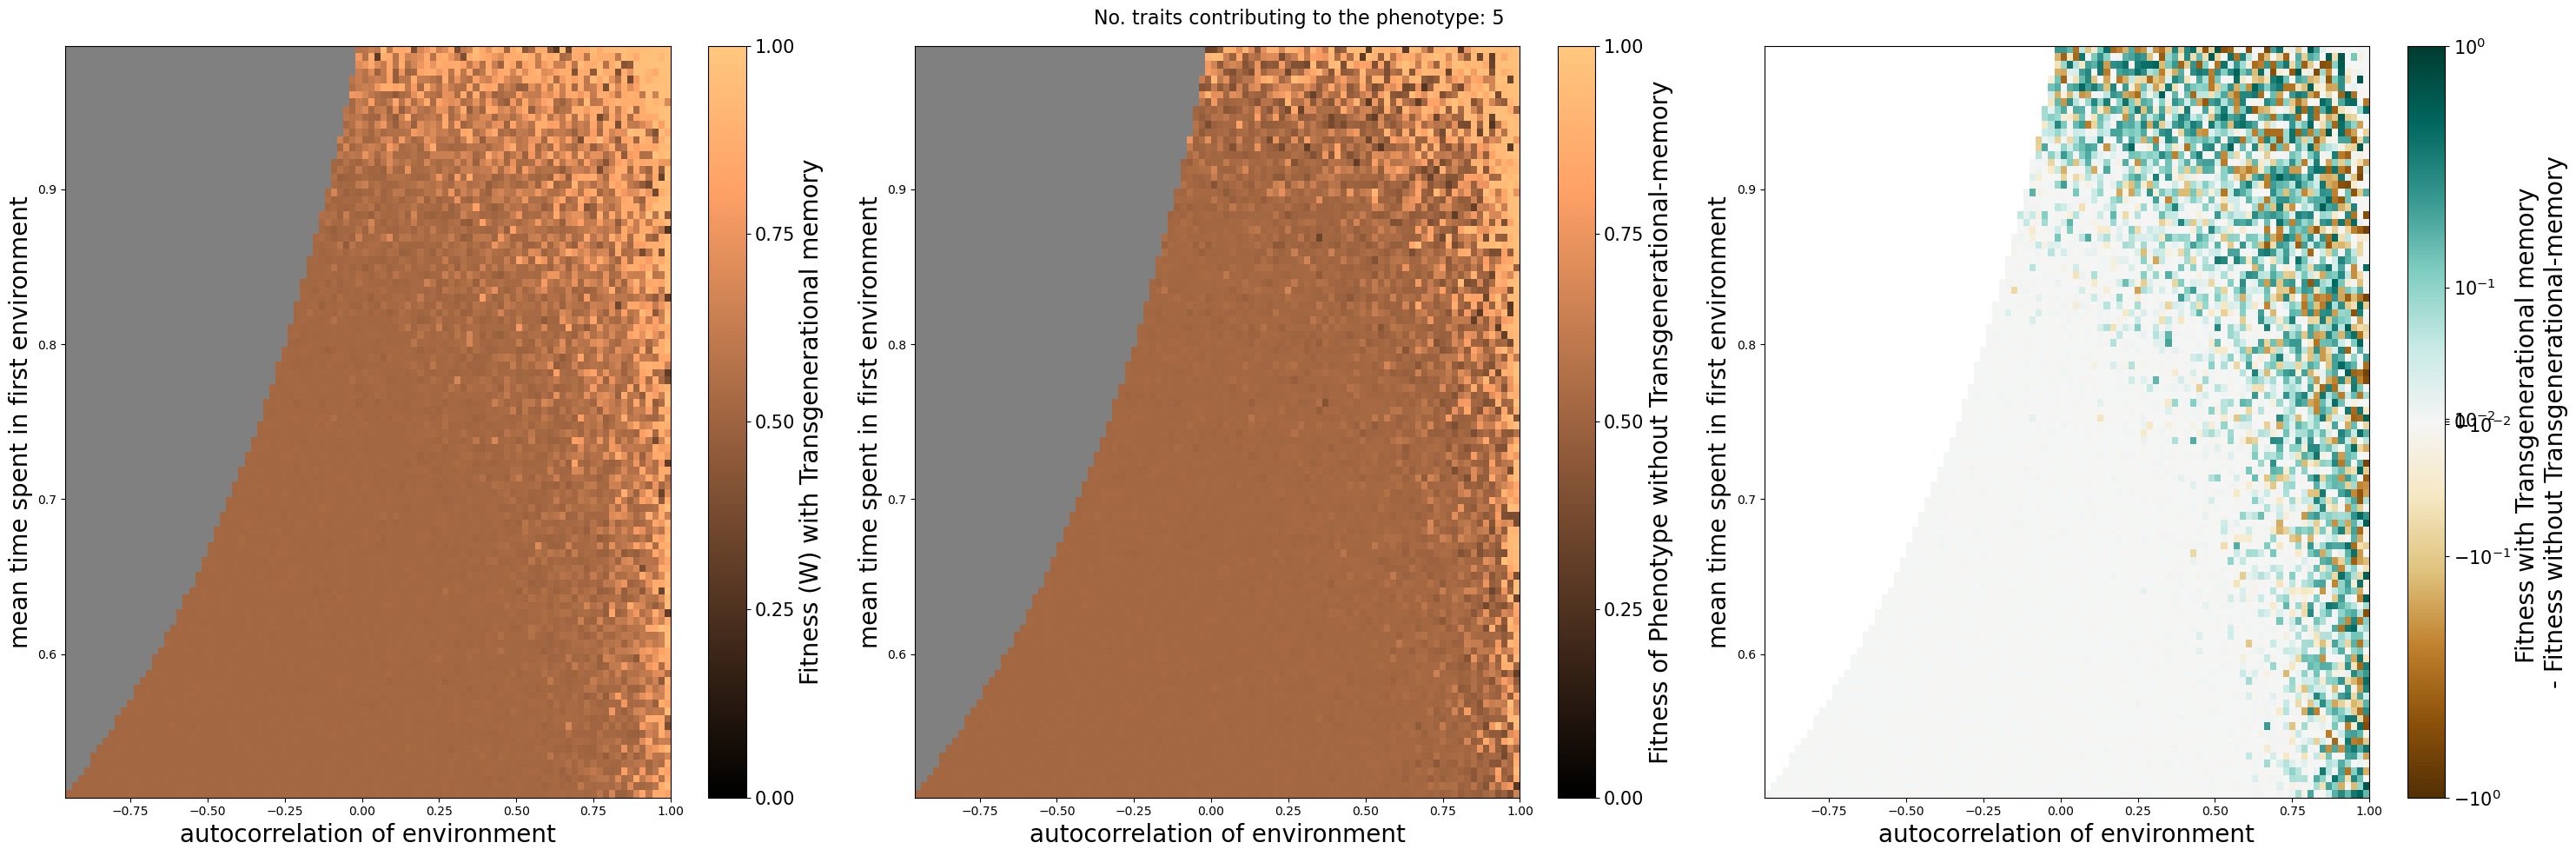

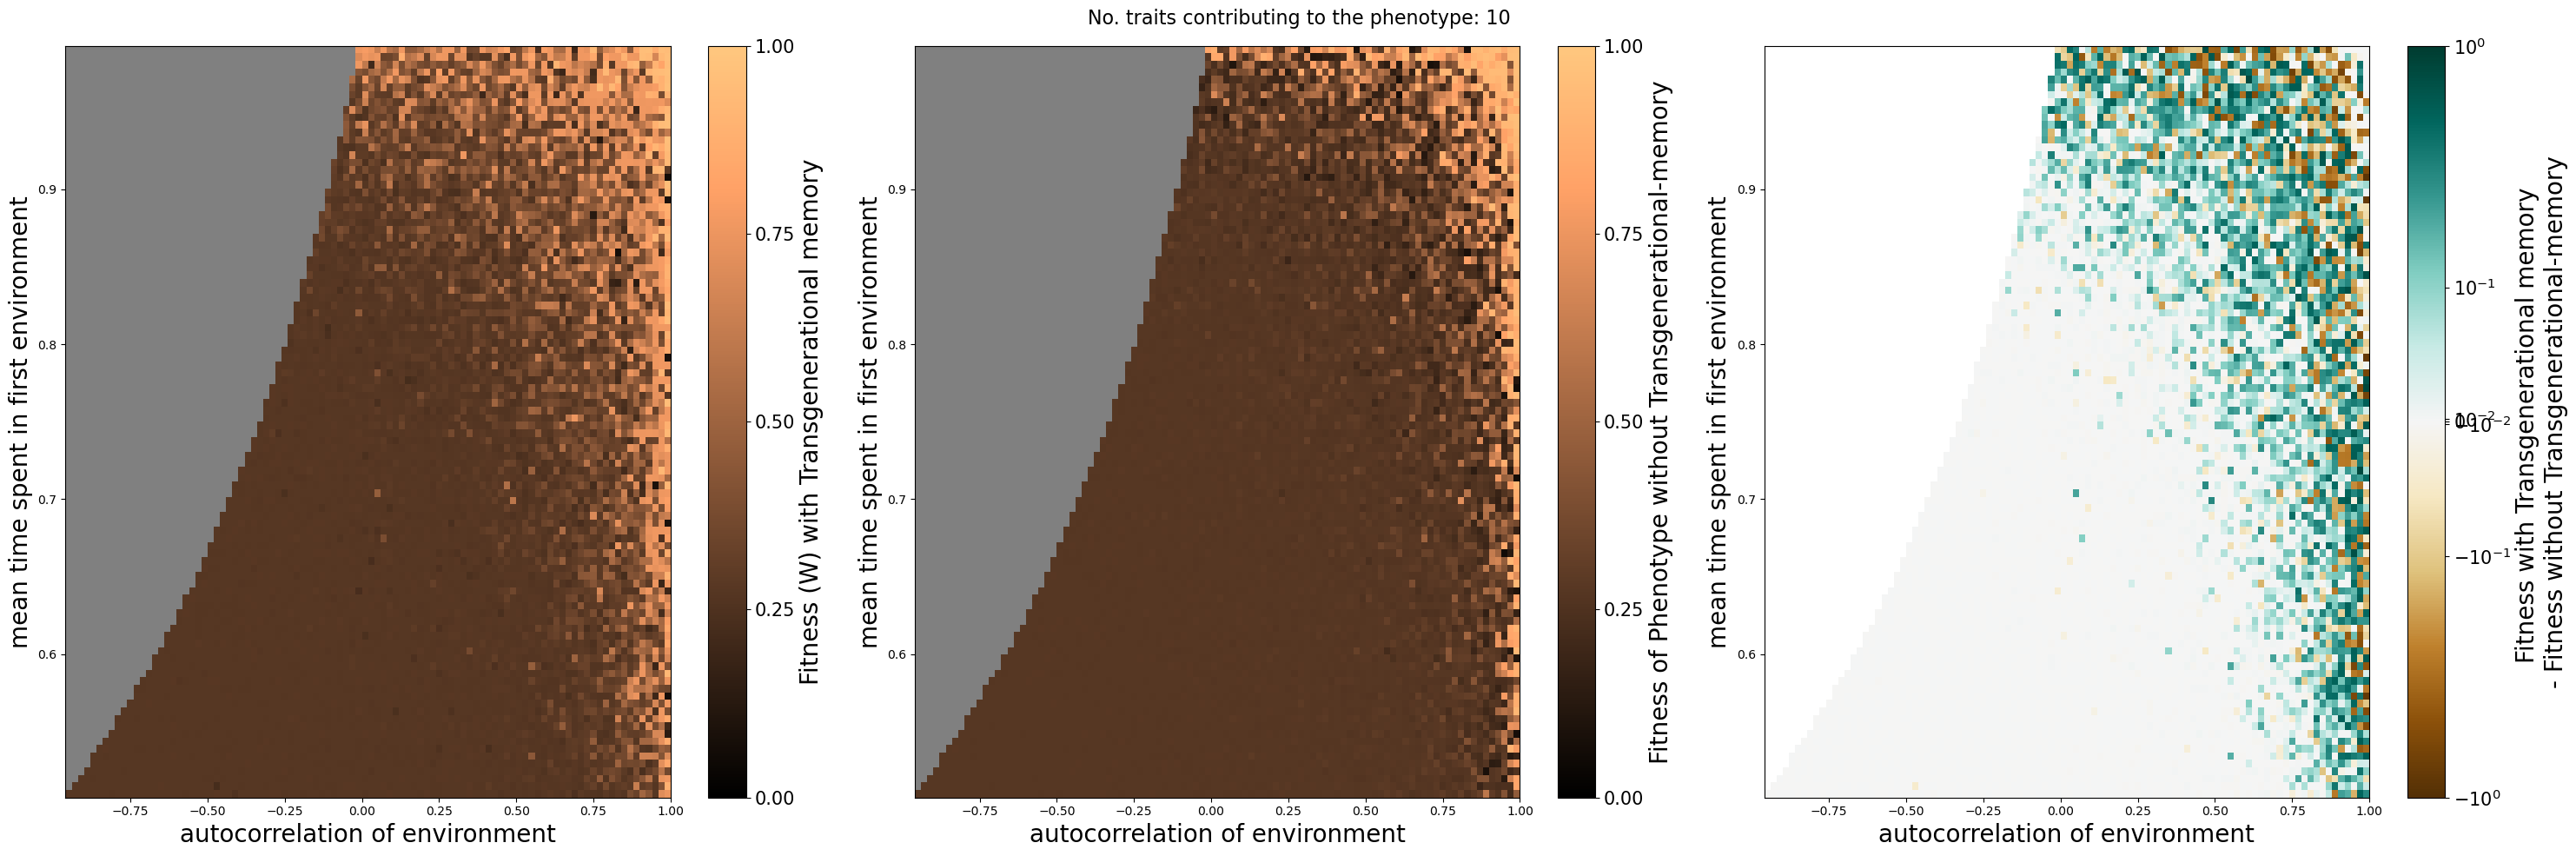

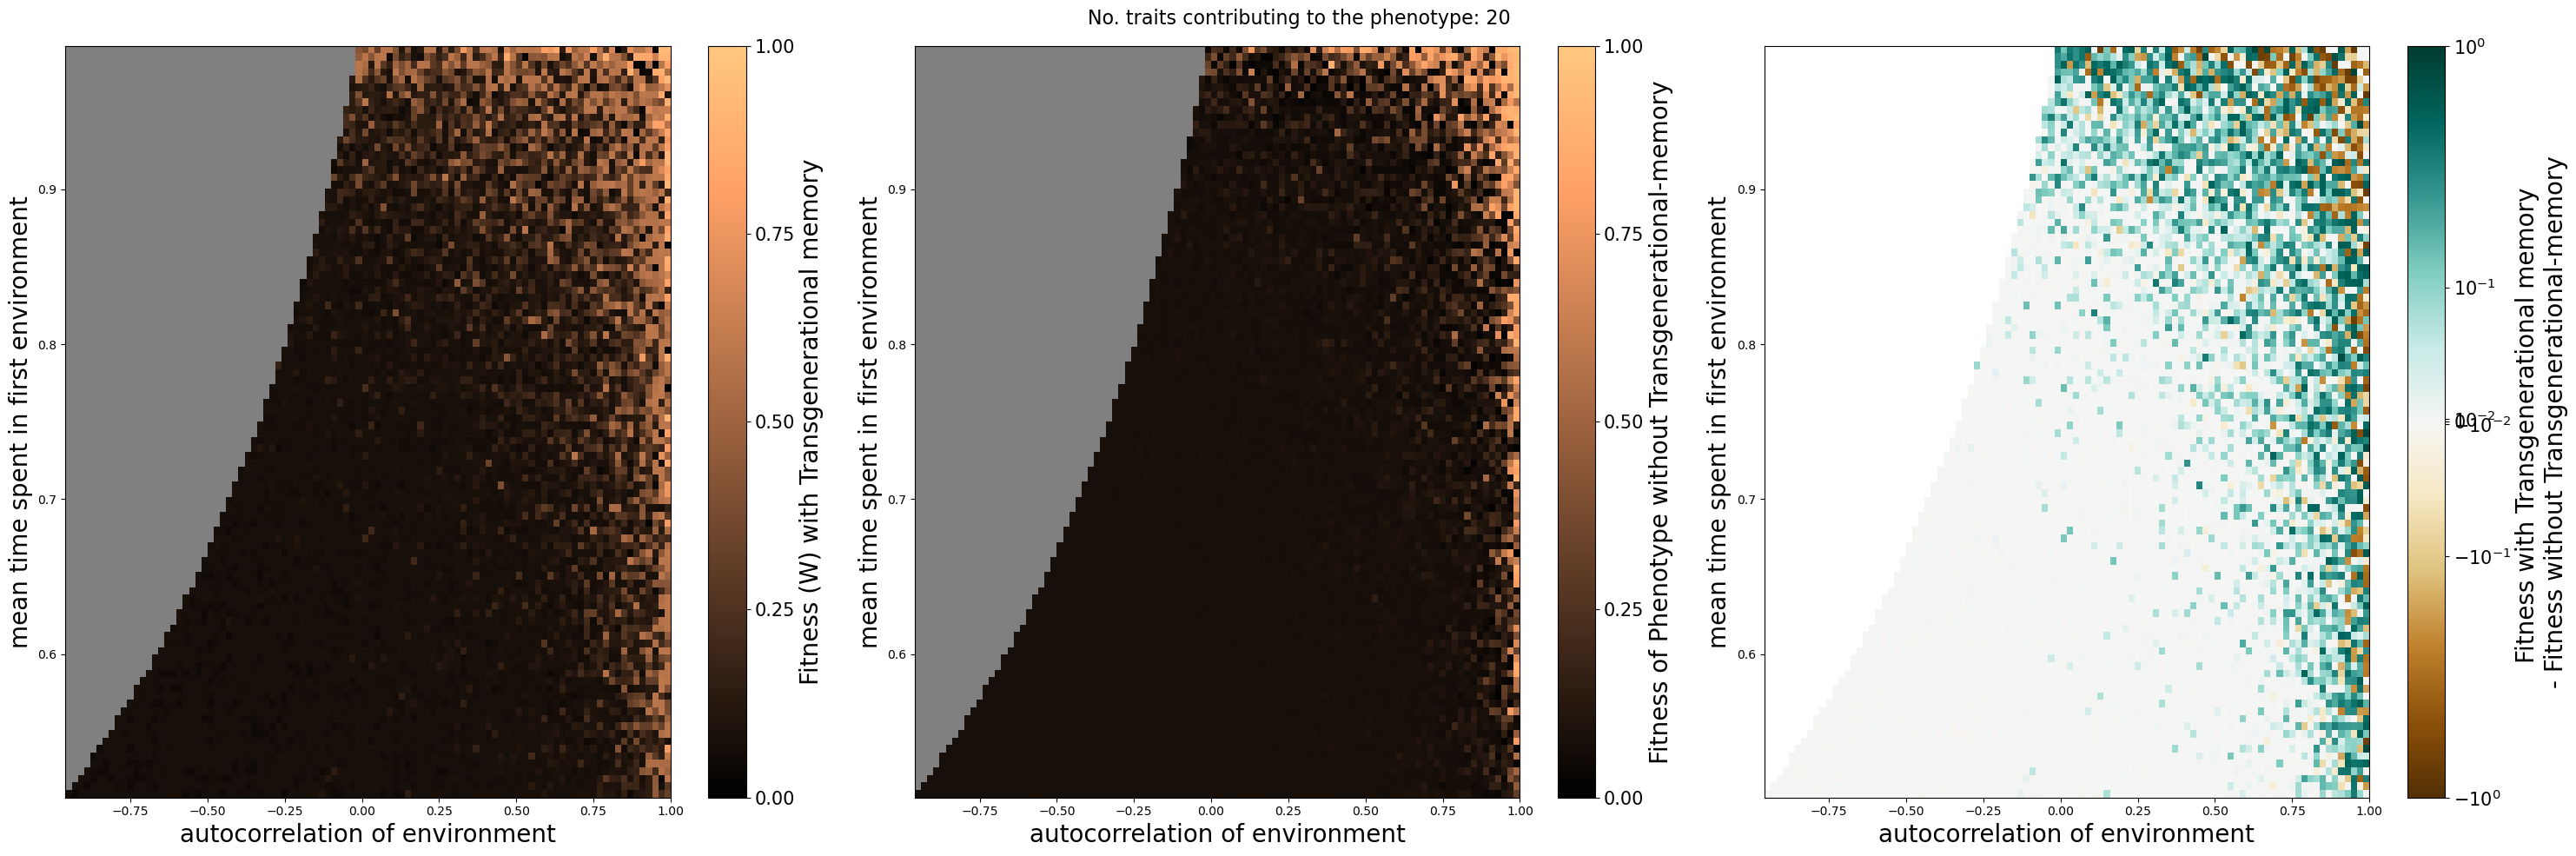

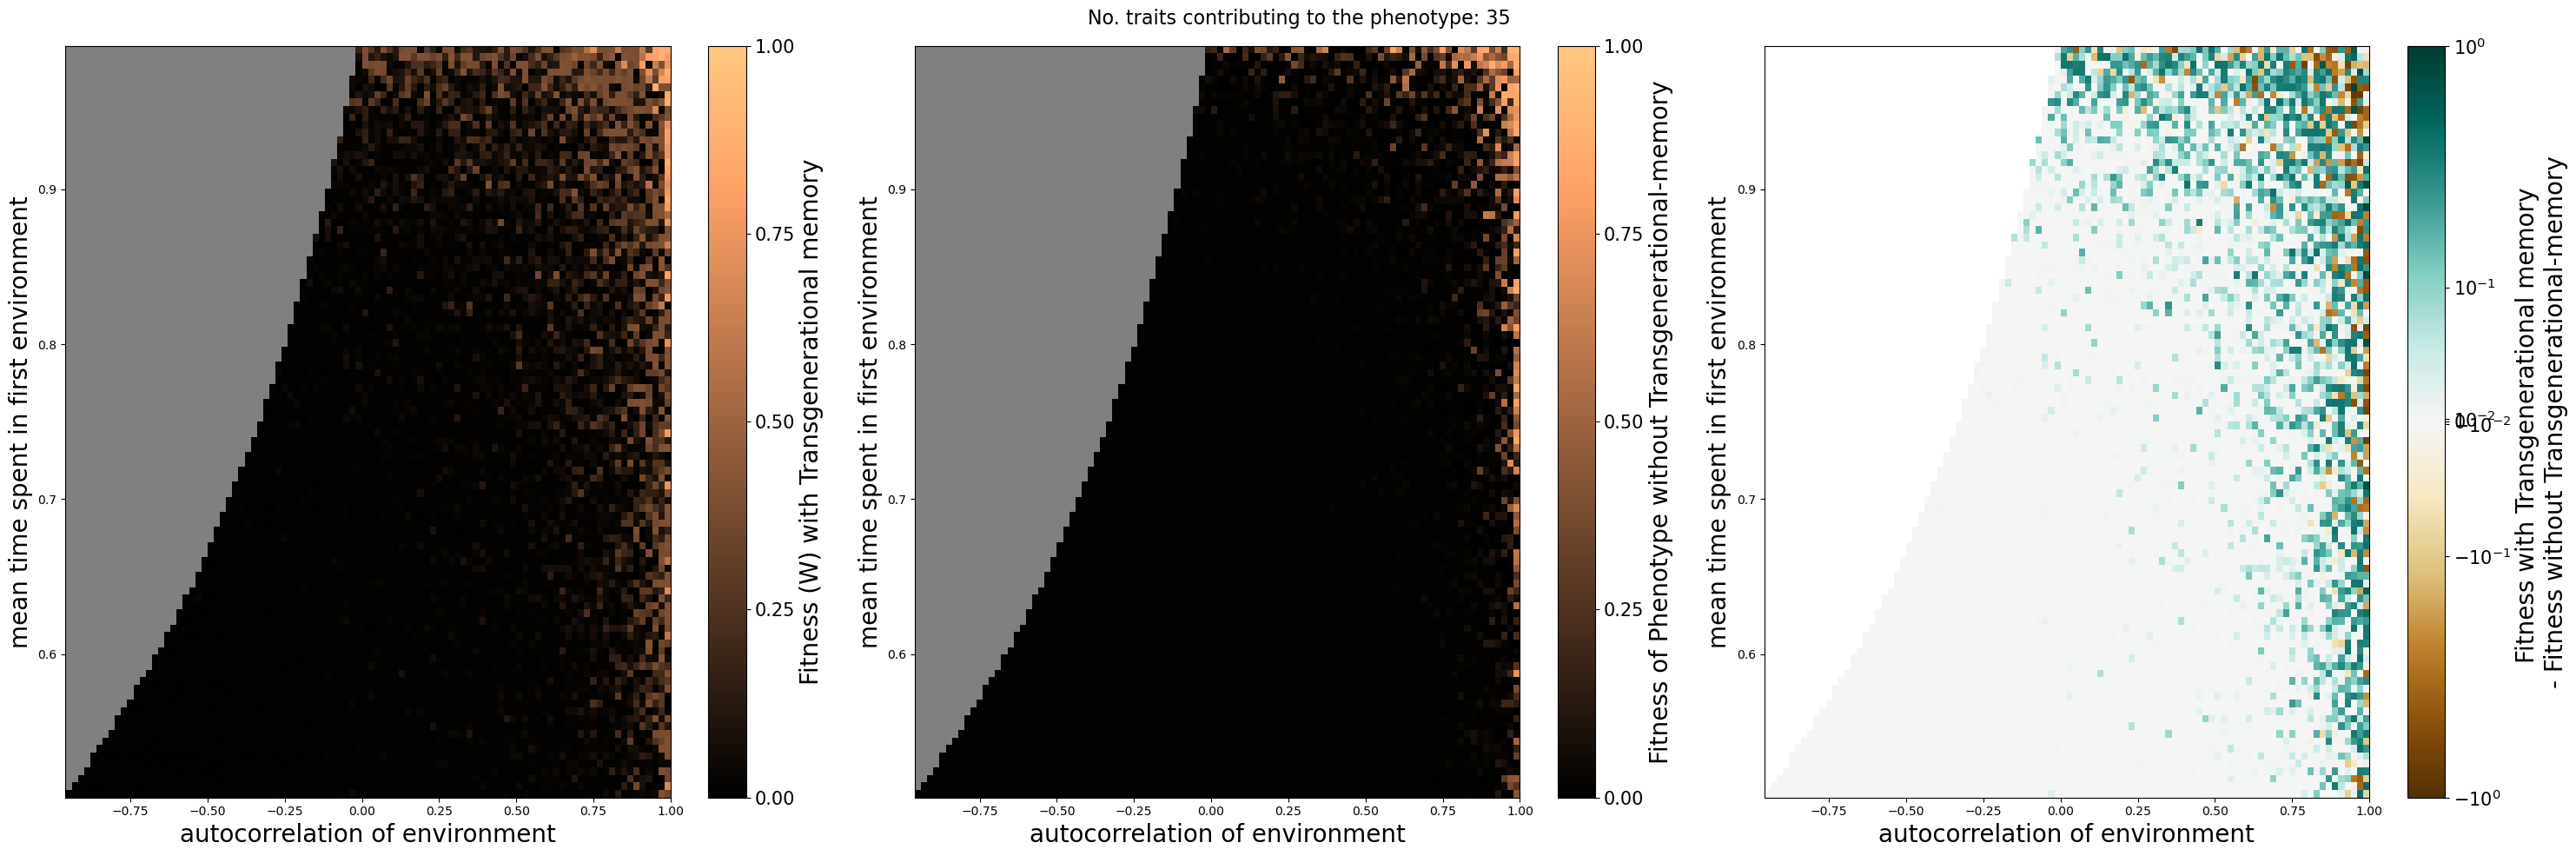

In [ ]:
dim_delta_fitness = []
axis_label_size =20
size =15

for i in dims:
    
    df_epi = epi_obj[f"epi_{i}"]
    df_gen = onlygen_obj[f"gen_{i}"]   # adjust key if needed

    fig, ax = plt.subplots(1, 3, figsize=(30, 10))
    fig.suptitle(
        f"No. traits contributing to the phenotype: {i}",
        fontsize=16
    )
    fig.subplots_adjust(top=0.90)

    cmap1 = plt.cm.copper.copy()
    cmap1.set_bad(color='gray')

    cmap2 = plt.cm.viridis.copy()
    cmap2.set_bad(color='gray')
 

    # --- (0,0) fitness ---
    pivoted_fitness = df_epi.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)

    max_abs = np.nanmax(np.ma.masked_less_equal(pivoted_fitness.values,0))
    min_abs = np.nanmin(np.ma.masked_less_equal(pivoted_fitness.values,0))


    norm = mcolors.Normalize(vmin=0, vmax=1)

    pcm1 = ax[0].pcolormesh(
        pivoted_fitness.columns,
        pivoted_fitness.index,
        pivoted_fitness.values,
        cmap=cmap1, norm=norm, shading='auto'
    )
    cbar0 = fig.colorbar(pcm1, ax=ax[0],
                 label='Fitness (W) with Transgenerational memory',
                 ticks=[0,0.25,0.5,0.75,1.0])
    cbar0.set_label('Fitness (W) with Transgenerational memory', fontsize=20)
    cbar0.ax.tick_params(labelsize=size)
    #ax[0].set_title(r'Fitness of Phenotype with Transgenerational-memory')
    ax[0].set_ylabel('mean time spent in first environment', fontsize=axis_label_size)
    ax[0].set_xlabel('autocorrelation of environment', fontsize=axis_label_size)

    # --- (0,1) genetic fitness ---
    pivoted_gen = df_gen.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)

    pcm2 = ax[1].pcolormesh(
        pivoted_gen.columns,
        pivoted_gen.index,
        pivoted_gen.values,
        cmap=cmap1, norm=norm, shading='auto'
    )
    cbar1 = fig.colorbar(pcm2, ax=ax[1],
                 label='Fitness of Phenotype without Transgenerational-memory',
                 ticks=[0,0.25,0.5,0.75,1.0])

    cbar1.set_label('Fitness of Phenotype without Transgenerational-memory', fontsize=20)
    cbar1.ax.tick_params(labelsize=size)
    ax[1].set_ylabel('mean time spent in first environment', fontsize=axis_label_size)
    ax[1].set_xlabel('autocorrelation of environment', fontsize=axis_label_size)

    
    # --- (2) fitness ---
    pivoted_fitness_subtracted = pivoted_fitness - pivoted_gen

    # symmetric normalization around 0
    max_abs = np.nanmax(np.abs(pivoted_fitness_subtracted.values))
    norm_diff = mcolors.SymLogNorm(linthresh=0.03, linscale=0.03,
                                              vmin=-1.0, vmax=1.0, base=10)

    pcm_diff = ax[2].pcolormesh(
        pivoted_fitness_subtracted.columns,
        pivoted_fitness_subtracted.index,
        pivoted_fitness_subtracted.values,
        cmap='BrBG',   # diverging colormap
        norm=norm_diff,
        shading='auto'
    )
        # Fixed boolean logic with proper parentheses
    condition_epi = (
        ((df_epi['rho'] > 0.75) & (df_epi['rho'] < 0.90) & (df_epi['m'] > 0.5) ) | 
        ((df_epi['m'] > 0.85) & (df_epi['rho'] < 0.90) & (df_epi['rho'] > -0.25) )
    )
    condition_gen = (
        ((df_gen['rho'] > 0.75) & (df_gen['rho'] < 0.90) & (df_gen['m'] > 0.5) ) | 
        ((df_gen['m'] > 0.85) & (df_gen['rho'] < 0.90) & (df_gen['rho'] > -0.25) )
    )
    
    delta_fitness = df_epi[condition_epi]['fitness'] - df_gen[condition_gen]['fitness']
    
    
    n_pos = (delta_fitness.values > 0.02564103).sum()
    n_neg = (delta_fitness.values < -0.02564103).sum()
    
    dim_delta_fitness.append([i , n_pos, n_neg])
    
    cbar2= fig.colorbar(
        pcm_diff,
        ax=ax[2]
    )
    cbar2.set_label('Fitness with Transgenerational memory \n- Fitness without Transgenerational-memory', fontsize=20)
    cbar2.ax.tick_params(labelsize=size)
    #ax[2].set_title('Fitness difference (Epi − Gen)')
    ax[2].set_ylabel('mean time spent in first environment', fontsize=axis_label_size)
    ax[2].set_xlabel('autocorrelation of environment', fontsize=axis_label_size)

    plt.tight_layout()
    #plt.savefig(f'/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Figures/finegrain_dims/Delta_Fitness_Epi-Gen_dim{i}')
    plt.show()

In [ ]:
 np.nanmin(np.ma.masked_less_equal(pivoted_fitness.values,0))

np.float64(0.7632914634357847)

In [ ]:
n_pos = np.array([d[1] for d in dim_delta_fitness])

n_pos

array([ 530,  815,  923, 1042, 1177, 1226,  960])

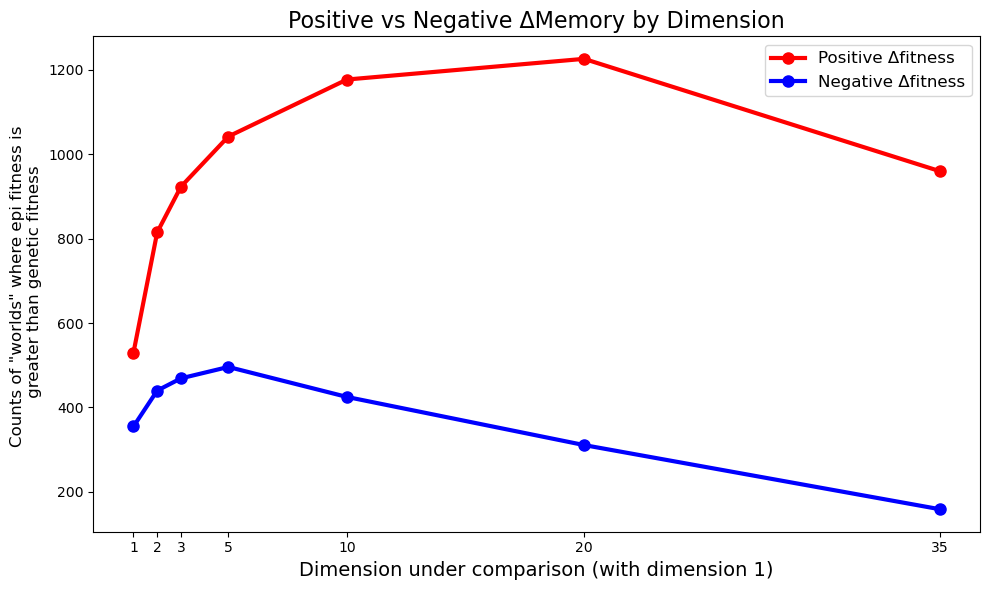

In [ ]:
# Extract all three columns properly
dim = np.array([d[0] for d in dim_delta_fitness])
n_pos = np.array([d[1] for d in dim_delta_fitness])
n_neg = np.array([d[2] for d in dim_delta_fitness])

# Complete figure with both positive/negative + proper axes
plt.figure(figsize=(10, 6))
plt.plot(dim, n_pos, 'ro-', linewidth=3, markersize=8, label='Positive Δfitness')
plt.plot(dim, n_neg, 'bo-', linewidth=3, markersize=8, label='Negative Δfitness')
plt.xlabel('Dimension', fontsize=14)
plt.ylabel('Counts of "worlds" where epi fitness is \n greater than genetic fitness' , fontsize=12)
#plt.ylim(0,600)
plt.title('Positive vs Negative ΔMemory by Dimension', fontsize=16)
plt.legend(fontsize=12)
plt.xticks(dim)  # Show all dimension ticks
plt.tight_layout()
plt.show()

#### Trans-memory vs fitness difference

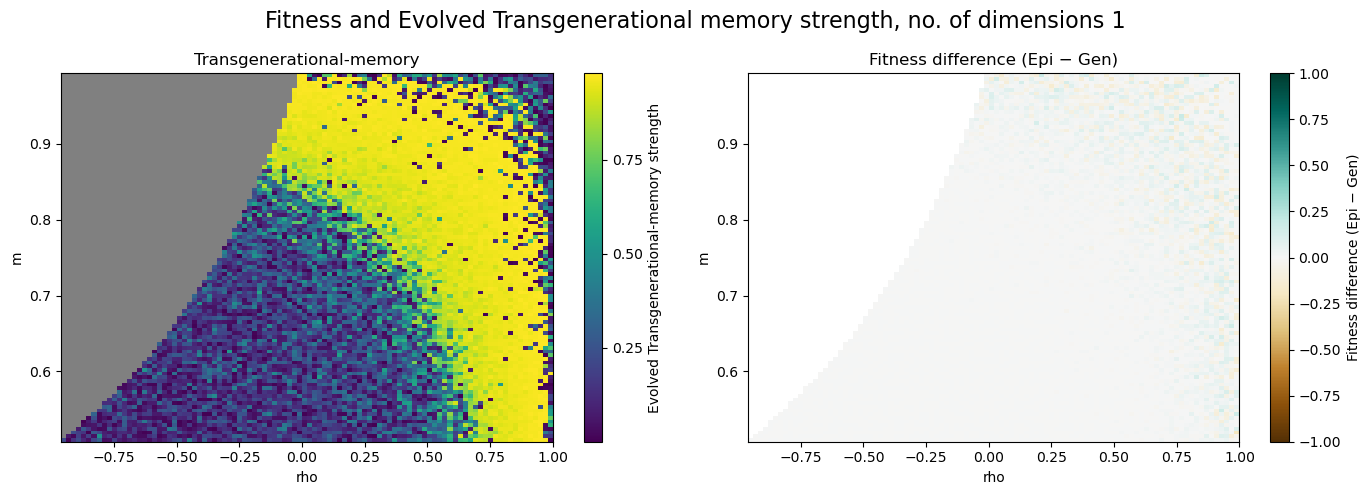

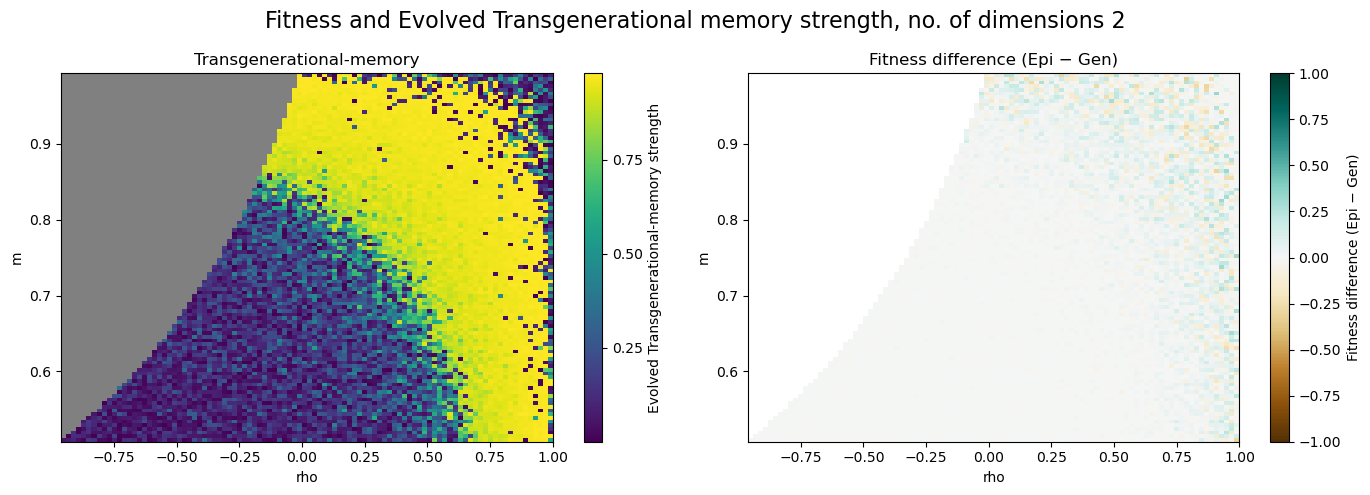

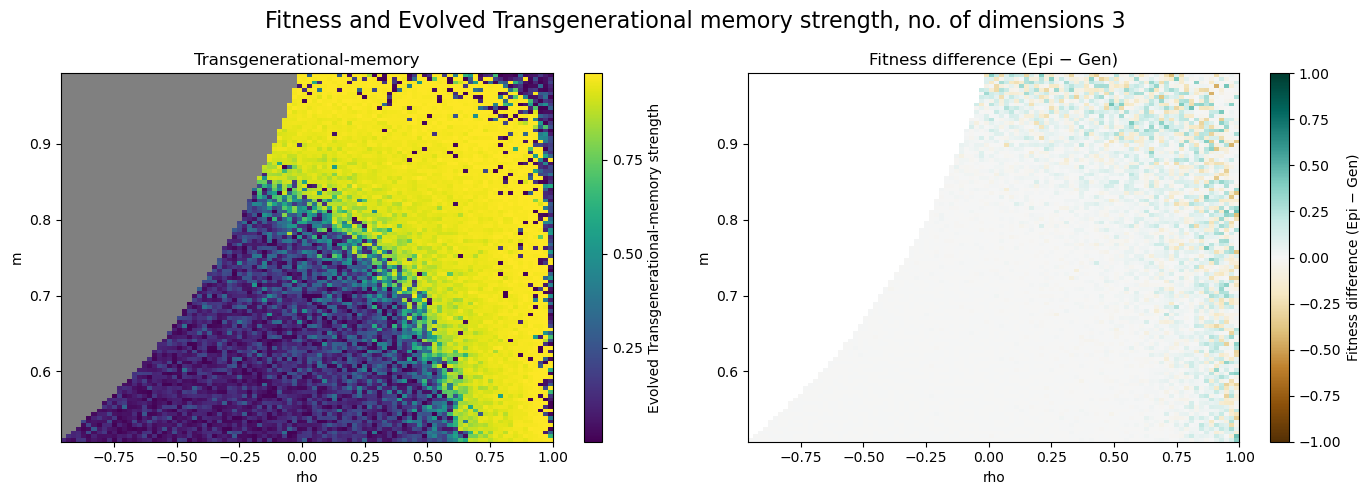

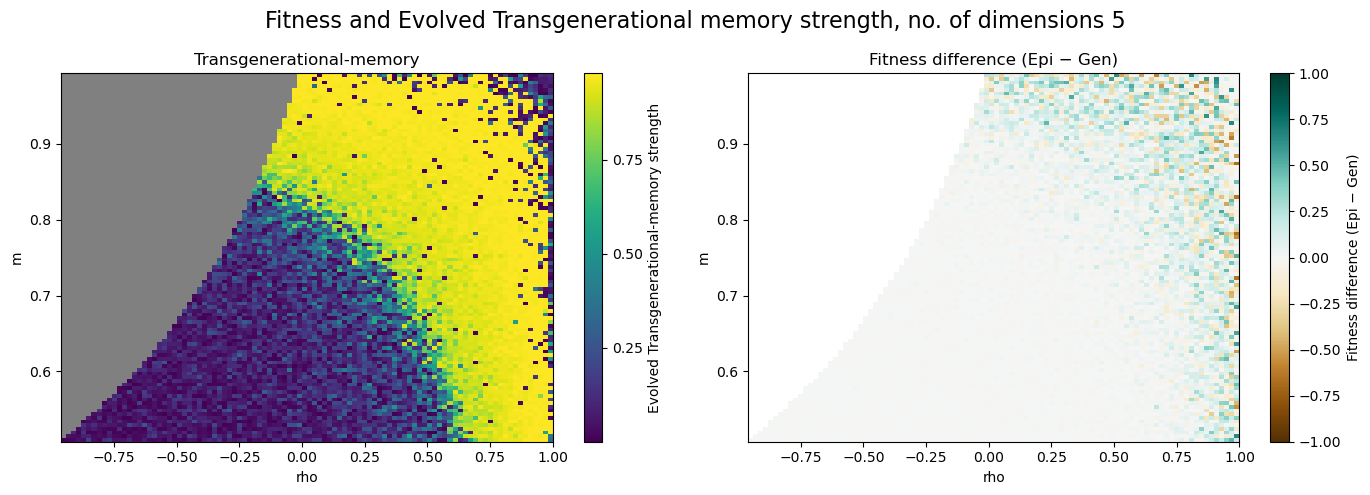

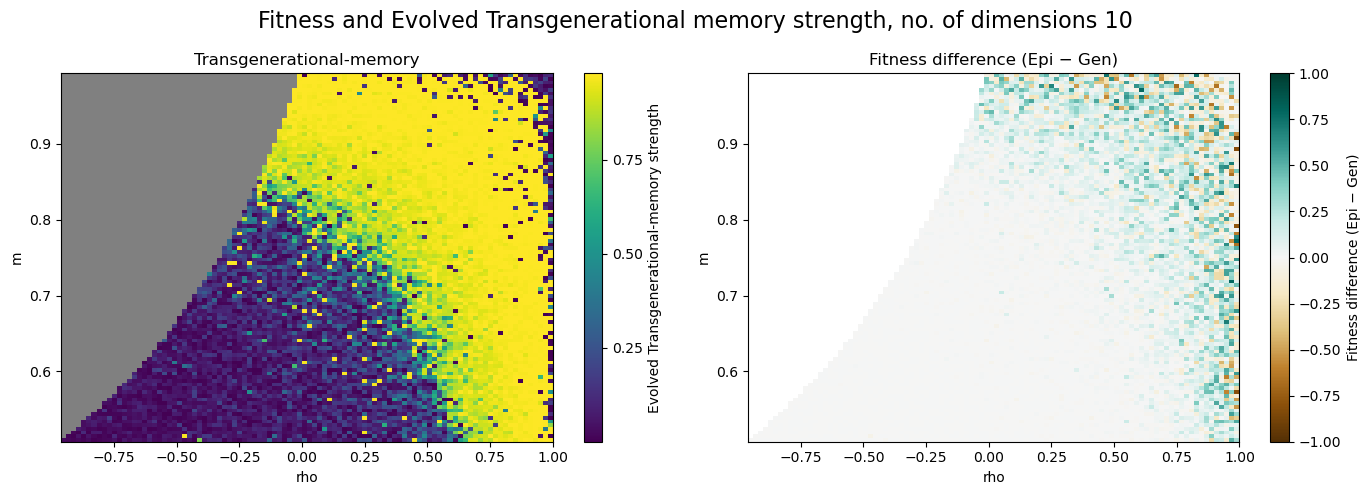

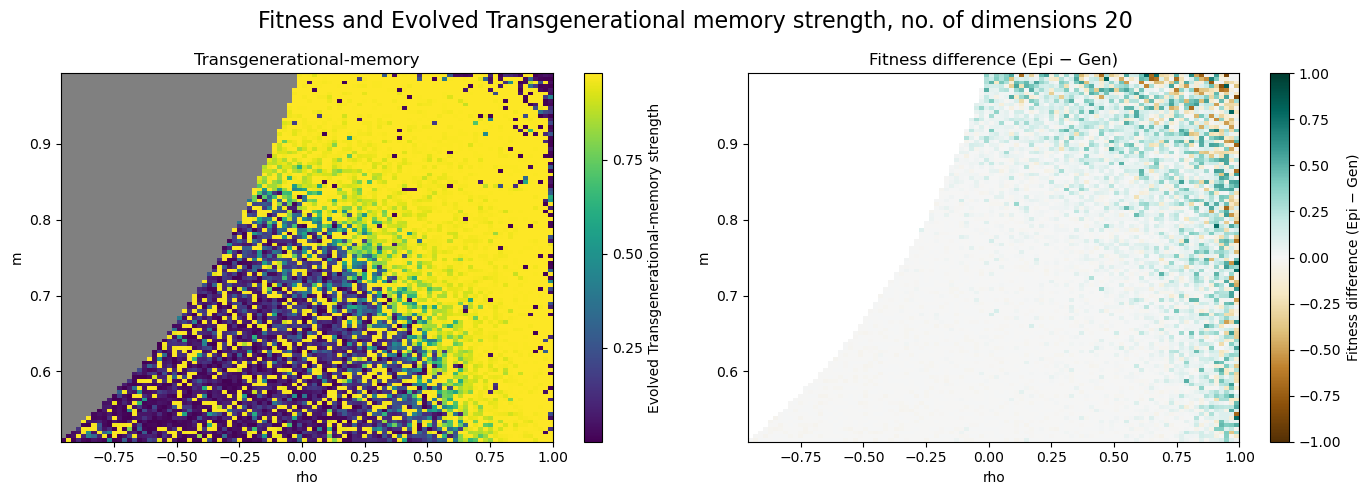

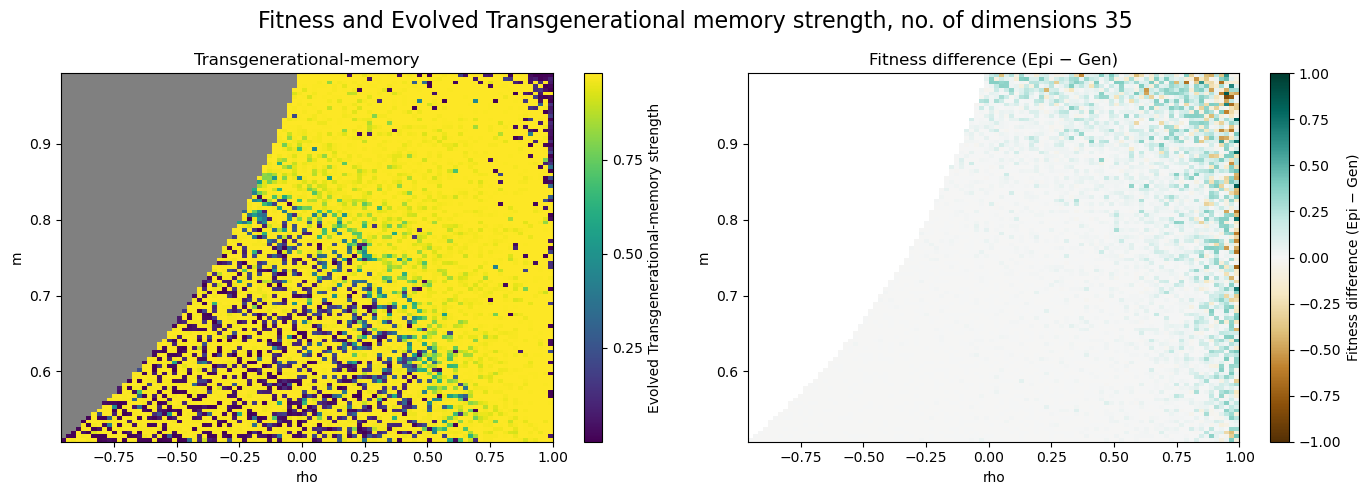

In [ ]:
for i in dims:
    
    df_epi = epi_obj[f"epi_{i}"]
    df_gen = onlygen_obj[f"gen_{i}"]   # adjust key if needed

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(
        f"Fitness and Evolved Transgenerational memory strength, no. of dimensions {i}",
        fontsize=16
    )
    fig.subplots_adjust(top=0.90)

    cmap1 = plt.cm.copper.copy()
    cmap1.set_bad(color='gray')

    cmap2 = plt.cm.viridis.copy()
    cmap2.set_bad(color='gray')

    # --- (1,0) epimem ---
    pivoted_epi = df_epi.pivot_table(
        index='m', columns='rho', values='epi_mem_p'
    ).sort_index().sort_index(axis=1)

    pcm3 = ax[0].pcolormesh(
        pivoted_epi.columns,
        pivoted_epi.index,
        pivoted_epi.values,
        cmap=cmap2,  shading='auto'
    )
    fig.colorbar(pcm3, ax=ax[0],
                 label='Evolved Transgenerational-memory strength',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[0].set_title('Transgenerational-memory')
    ax[0].set_ylabel('m')
    ax[0].set_xlabel('rho')
    
    pivoted_fitness = df_epi.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)

    # --- (0,1) genetic fitness ---
    pivoted_gen = df_gen.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)
    
    # --- (2) fitness ---
    pivoted_fitness_subtracted = pivoted_fitness - pivoted_gen

    # symmetric normalization around 0
    max_abs = np.nanmax(np.abs(pivoted_fitness_subtracted.values))
    norm_diff = mcolors.TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)

    pcm_diff = ax[1].pcolormesh(
        pivoted_fitness_subtracted.columns,
        pivoted_fitness_subtracted.index,
        pivoted_fitness_subtracted.values,
        cmap='BrBG',   # diverging colormap
        norm=norm_diff,
        shading='auto'
    )

    fig.colorbar(
        pcm_diff,
        ax=ax[1],
        label='Fitness difference (Epi − Gen)'
    )
    
    ax[1].set_title('Fitness difference (Epi − Gen)')
    ax[1].set_ylabel('m')
    ax[1].set_xlabel('rho')


    plt.tight_layout()
    plt.savefig(f'/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Figures/finegrain_dims/Delta_Fitness_Epi-Gen_dim{i}_wmemory')
    plt.show()

In [ ]:
for i in dims:
    
    df_epi = epi_obj[f"epi_{i}"]
    df_gen = onlygen_obj[f"gen_{i}"]   # adjust key if needed

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(
        f"Fitness and Evolved Transgenerational memory strength, no. of dimensions {i}",
        fontsize=16
    )
    fig.subplots_adjust(top=0.90)

    cmap1 = plt.cm.copper.copy()
    cmap1.set_bad(color='gray')

    cmap2 = plt.cm.viridis.copy()
    cmap2.set_bad(color='gray')

    # --- (1,0) epimem ---
    pivoted_epi = df_epi.pivot_table(
        index='m', columns='rho', values='epi_mem_p'
    ).sort_index().sort_index(axis=1)

    pcm3 = ax[0].pcolormesh(
        pivoted_epi.columns,
        pivoted_epi.index,
        pivoted_epi.values,
        cmap=cmap2,  shading='auto'
    )
    fig.colorbar(pcm3, ax=ax[0],
                 label='Evolved Transgenerational-memory strength',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[0].set_title('Transgenerational-memory')
    ax[0].set_ylabel('m')
    ax[0].set_xlabel('rho')

#### Standard deviation

In [ ]:
df_epi.shape[0]

6919

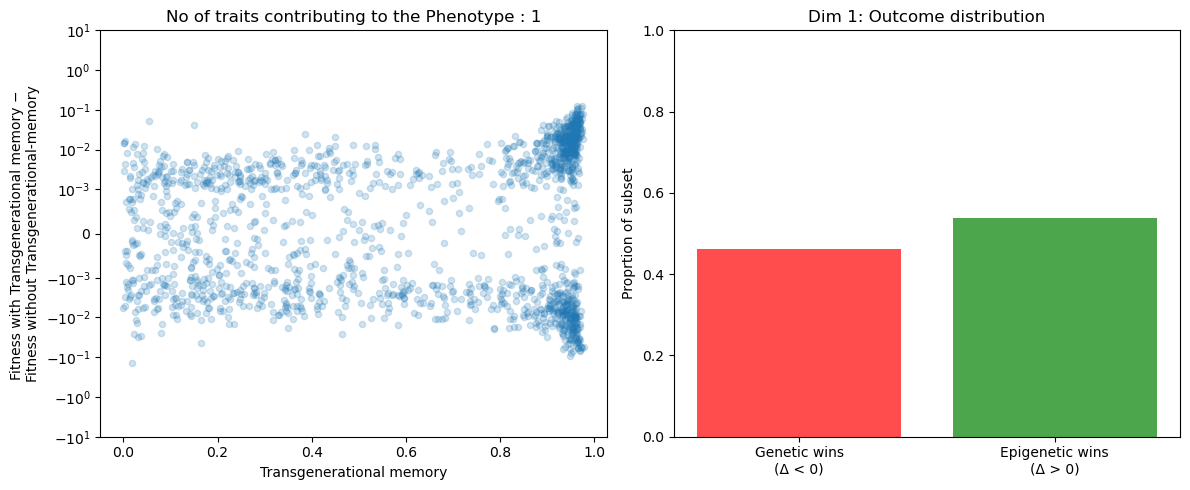

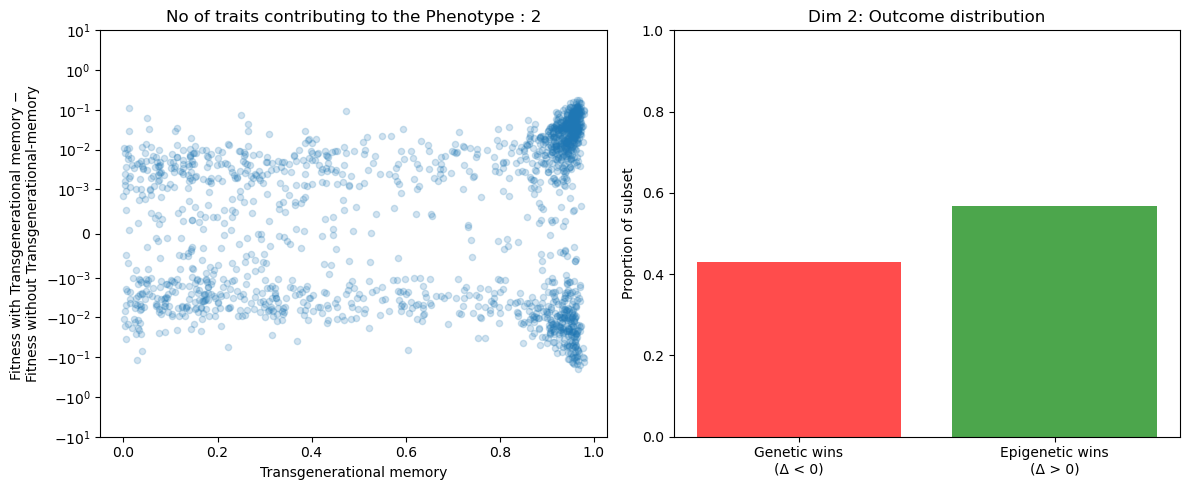

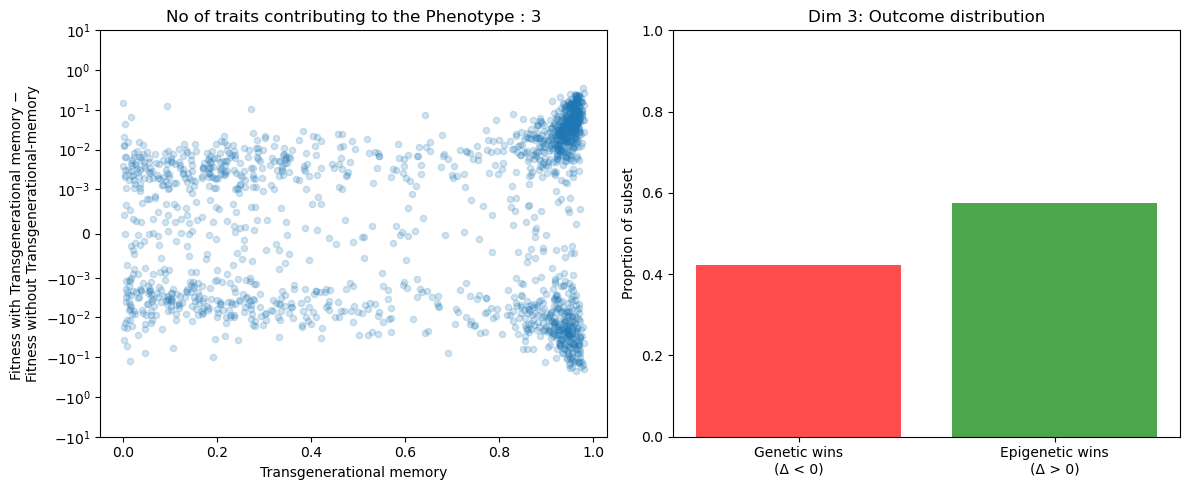

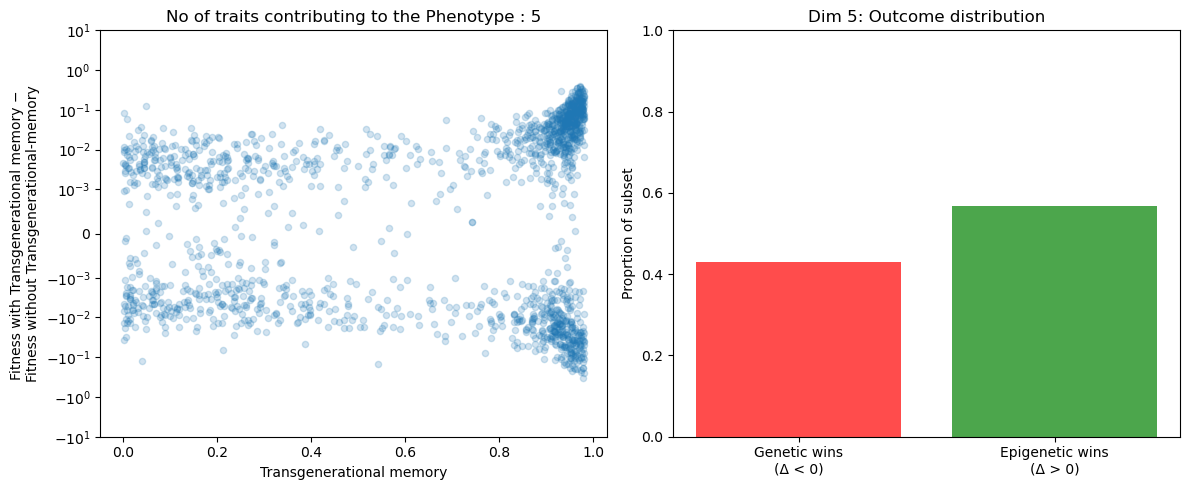

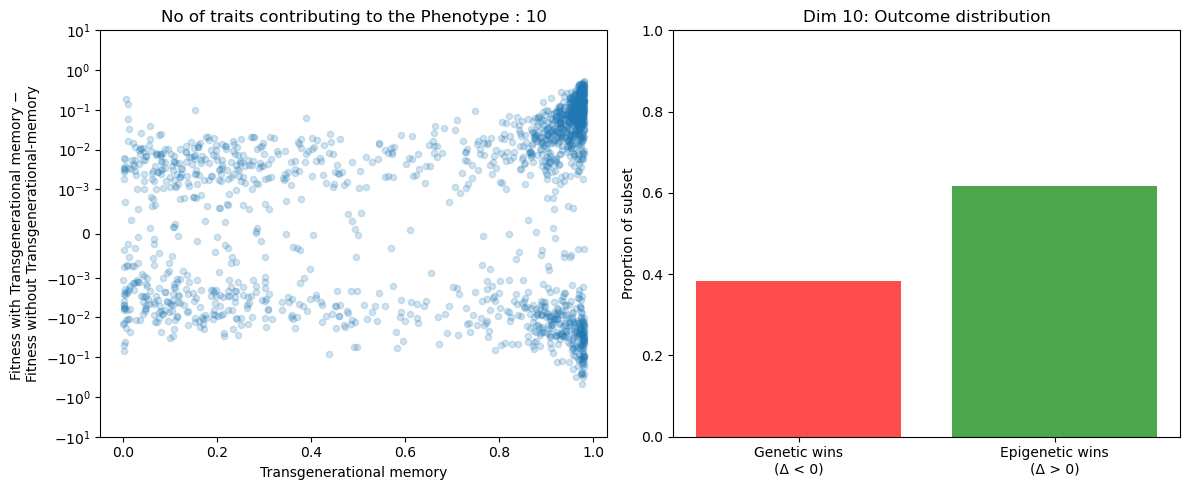

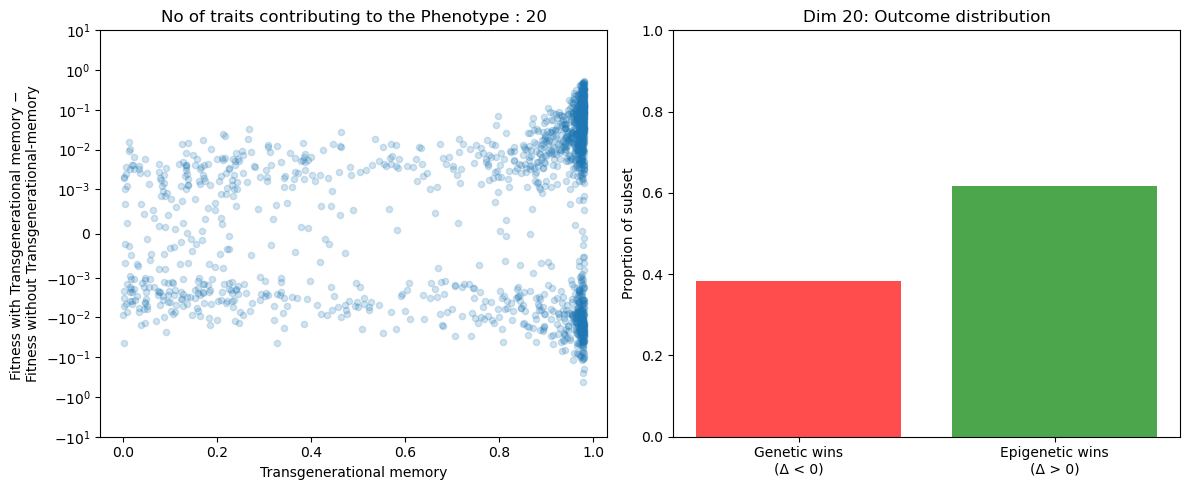

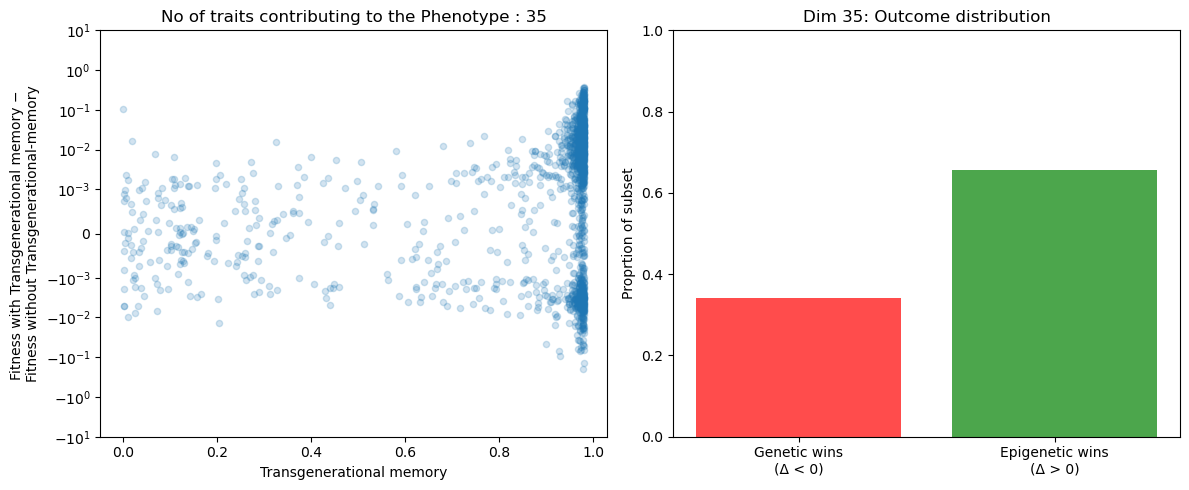

In [ ]:

hi_pos_neg = []

for i in dims:  # Fixed: was "or i"
    df_epi = epi_obj[f"epi_{i}"]
    df_gen = onlygen_obj[f"gen_{i}"]

    df_epi['delta_fitness'] = df_epi['fitness'] - df_gen['fitness']
    
    # Fixed boolean logic with proper parentheses
 
    #print(len(epi_comp['delta_memory']))
    condition = (((df_epi['rho'] > 0.25) & (df_epi['rho'] < 0.9) &  (df_epi['m'] < 0.75)) |
                ( ((df_epi['rho']) > -0.25) & (df_epi['rho']) < 0.6) & ((df_epi['m']) > 0.75) &  ((df_epi['m']) < 0.9) )                            
    
    
    delta_fitness = df_epi[condition]
    no_worlds = delta_fitness.shape[0]
    
    #collect data
    n_pos = (delta_fitness['delta_fitness'] > 0).sum() / no_worlds
    n_neg = (delta_fitness['delta_fitness'] < 0).sum() / no_worlds
    categories = ['Genetic wins\n(Δ < 0)', 'Epigenetic wins\n(Δ > 0)']
    counts = [n_neg, n_pos]
    colors = ['red', 'green']
    # worlds where memory is more than 0.9
    
    deltafitness_hi = delta_fitness[delta_fitness['epi_mem_p']> 0.9]
    
    n_hi_pos = (delta_fitness['delta_fitness'] > 0).sum() / no_worlds
    n_hi_neg = (delta_fitness['delta_fitness'] < 0).sum() / no_worlds
    props = [i, n_hi_pos, n_hi_neg]
    colors = ['red', 'green']
    hi_pos_neg.append(np.array(props))
    
    #plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    ax1.scatter(delta_fitness['epi_mem_p'], delta_fitness['delta_fitness'], 
               alpha=0.2, s=20)
    ax1.set_xlabel("Transgenerational memory")
    ax1.set_ylabel("Fitness with Transgenerational memory − \nFitness without Transgenerational-memory")
    ax1.set_yscale('symlog', linthresh=0.001)
    ax1.set_ylim(-10,10)
    ax1.set_title(f"No of traits contributing to the Phenotype : {i}")
    
  
    
    ax2.bar(categories, counts, color=colors, alpha=0.7)
    ax2.set_ylabel('Proprtion of subset')
    ax2.set_title(f'Dim {i}: Outcome distribution')
    ax2.set_ylim(0, 1)

    
    plt.tight_layout()
    plt.show()
    

In [ ]:
hist_counts

array([  0,   0,   0,   0,   0,   0,   0,   0,   2, 555, 975,  66,  21,
         7,   0,   0,   0,   0,   0,   0])

#### PLot proportion of subset worlds with high memory and delta fitness

In [ ]:
hi_pos_neg

[array([1.        , 0.53751538, 0.46248462]),
 array([2.        , 0.56888069, 0.43111931]),
 array([3.        , 0.57626076, 0.42373924]),
 array([5.        , 0.56888069, 0.43111931]),
 array([10.        ,  0.61685117,  0.38314883]),
 array([20.        ,  0.61746617,  0.38253383]),
 array([35.        ,  0.65744157,  0.34255843])]

/tmp/ipykernel_7291/3645717368.py:13: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0,10**1.7)


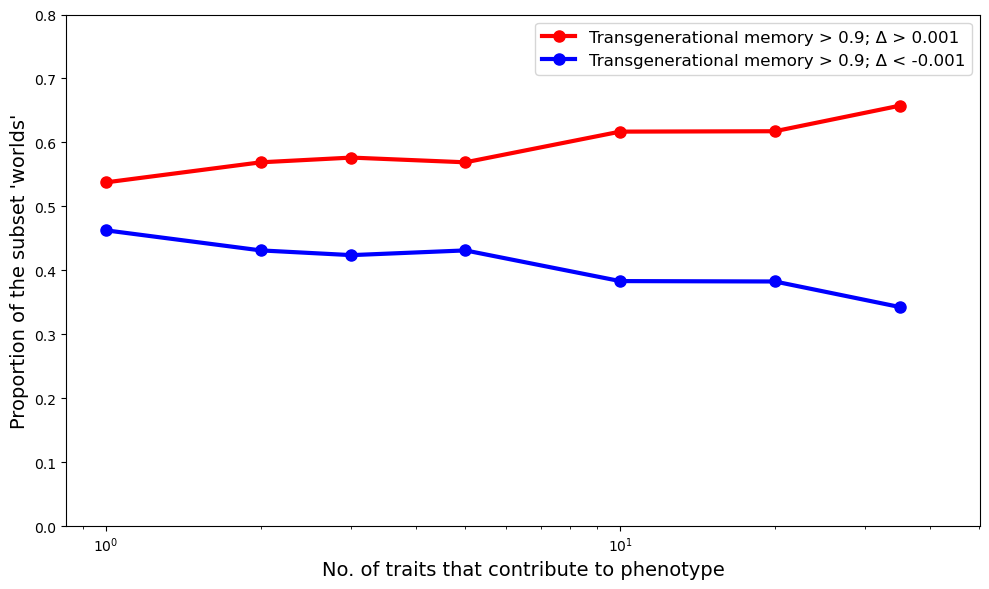

In [ ]:

dim = np.array([d[0] for d in hi_pos_neg])
prop_hi_array = np.array([d[1] for d in hi_pos_neg])
prop_lo_array = np.array([d[2] for d in hi_pos_neg])

# Complete figure with both positive/negative + proper axes
plt.figure(figsize=(10, 6))
plt.plot(dim, prop_hi_array, 'ro-', linewidth=3, markersize=8, label='Transgenerational memory > 0.9')
plt.plot(dim, prop_lo_array, 'bo-', linewidth=3, markersize=8, label='Transgenerational memory > 0.9')
plt.xlabel('No. of traits that contribute to phenotype', fontsize=14)
plt.ylabel("Proportion of the subset 'worlds'", fontsize=14)
plt.xscale('log')
plt.ylim(0,0.8)
plt.xlim(0,10**1.7)
plt.legend(fontsize=12)
#plt.xticks(compare_dim)  # Show all dimension ticks
plt.tight_layout()
plt.show()

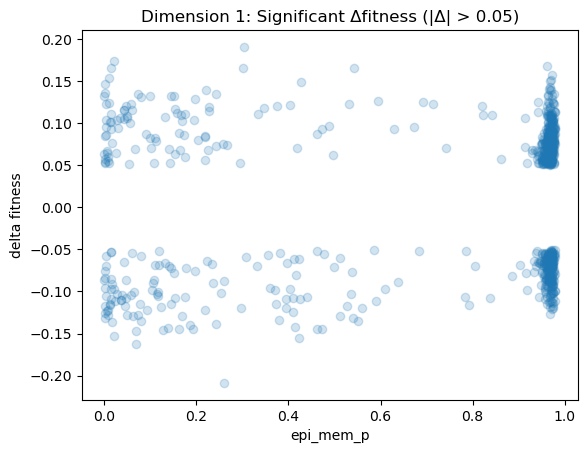

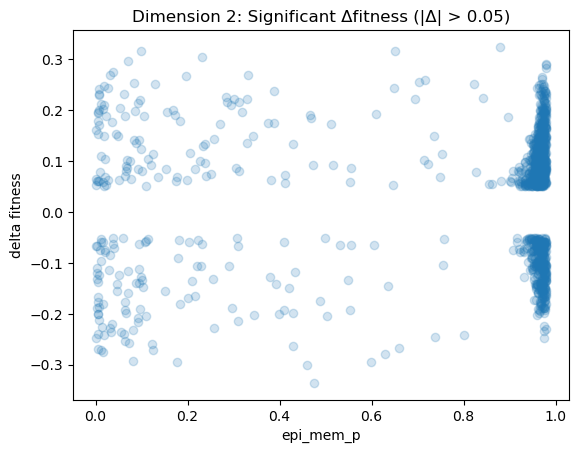

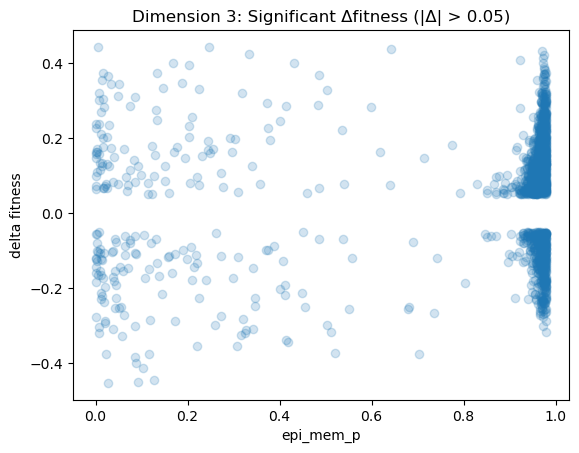

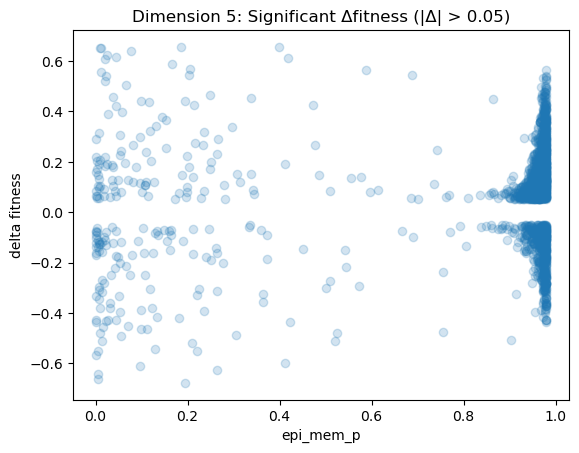

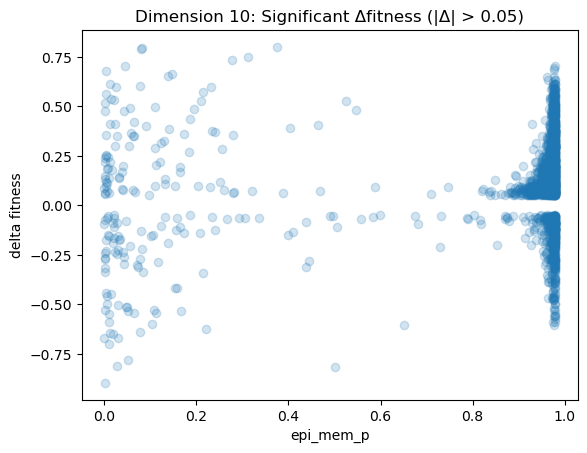

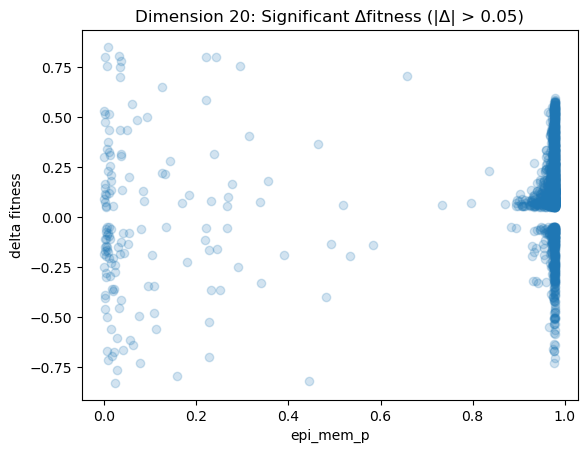

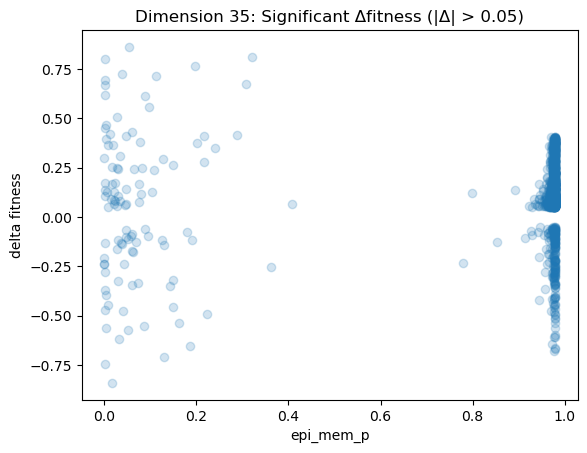

In [ ]:
for i in dims:
    df_epi = epi_obj[f"epi_{i}"]
    df_gen = onlygen_obj[f"gen_{i}"]

    epimem = df_epi['epi_mem_p']
    df_epi['delta_fitness'] = df_epi['fitness'] - df_gen['fitness']
    delta_fitness = df_epi[(df_epi['delta_fitness'] > 0.05) | (df_epi['delta_fitness'] < -0.05)]
    
    plt.scatter(delta_fitness['epi_mem_p'], delta_fitness['delta_fitness'], alpha=0.2)
    plt.xlabel("epi_mem_p")
    plt.ylabel("delta fitness")
    plt.title(f"Dimension {i}: Significant Δfitness (|Δ| > 0.05)")  # Added title
    plt.show()

Misc: fitness vs memory

In [ ]:

fig, axes = plt.subplots(7, 2, figsize=(12, 20))
axes = axes.ravel()

for j, i in enumerate(dims):
    df = epi_obj[f"epi_{i}"].copy()
    condition = (
        ((df["rho"] > 0.75) & (df["rho"] < 0.90) & (df["m"] > 0.5)) |
        ((df["m"] > 0.85) & (df["rho"] < 0.90) & (df["rho"] > -0.25))
    )
    
    # Left plot - memory
    axes[2*j].scatter(df[condition]["epi_mem_p"], df[condition]["fitness"], 
                     alpha=0.2, s=20)
    axes[2*j].set_title(f"Dim {i}")
    axes[2*j].set_ylim(0, 1)
    axes[2*j].set_xlabel('memory')
    axes[2*j].set_ylabel('fitness')
    
    # Right plot - neutral
    axes[2*j+1].scatter(df[condition]["neutral_trait_p"], df[condition]["fitness"], 
                       alpha=0.2, s=20)
    axes[2*j+1].set_title(f"Dim {i}")
    axes[2*j+1].set_ylim(0, 1)
    axes[2*j+1].set_xlabel('neutral')
    axes[2*j+1].set_ylabel('fitness')

plt.tight_layout()
plt.show()

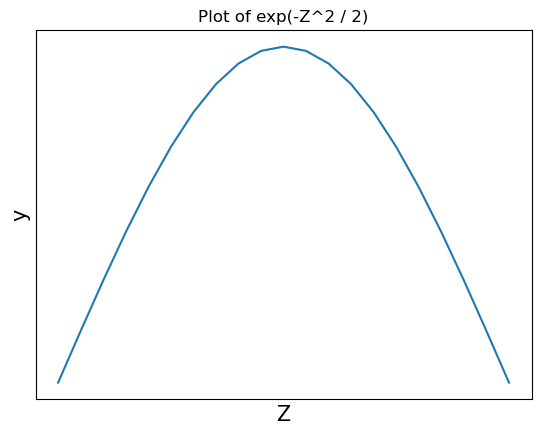

In [ ]:
Zopt = np.arange(-1, 1.1, 0.1)
y = np.exp(-Zopt**2 / 2)

plt.plot(Zopt, y)
plt.xlabel("Z", fontsize = 15)
plt.ylabel("y", fontsize = 15)
plt.title("Plot of exp(-Z^2 / 2)")
plt.xticks([]) 
plt.yticks([]) 

#plt.grid(True)
plt.savefig('fitness.svg', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [ ]:
task_id = 2  # SLURM_ARRAY_TASK_ID (0–78)
rows_per_job = 5
start_row = task_id * rows_per_job  # 200
end_row = min(start_row + rows_per_job, 6976)  # 300 or 6976
n_rows = end_row - start_row  # 100 (or fewer for last job)

file_path = '/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Plot_results/clean_data_env.txt'

# Read only the needed chunk
params_df = pd.read_csv(
    file_path,
    sep='\t',
    skiprows=range(1, start_row + 1),  # skip all rows *before* start_row (header at 0)
    nrows=n_rows,
   header=None)

# Now param_subset is just the whole params_df (since you already read only that chunk)
param_subset = params_df

In [ ]:
file_path = '/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/important_scripts/clean_data_env.txt'

params_df = pd.read_csv(
    file_path,
    sep='\t',
    chunksize=1000
)


AttributeError: 'TextFileReader' object has no attribute 'rows'

In [ ]:

for i in range(0, 8): 
    rows_per_job = 200
    start_row = i * rows_per_job
    end_row = min(start_row + rows_per_job, 1741)
    n_rows = end_row - start_row
     
    # Read only the needed chunk
    params_df = pd.read_csv(
        file_path,
        sep='\t',
        skiprows=range(1, start_row + 1),
        nrows=n_rows,
        header=None
    )

    # Check for NAs

    print(f"Chunk {i}: total NA entries: {params_df.isna().sum().sum()}\n")
    print(params_df.shape)
    print(end_row)

Chunk 0: total NA entries: 0

(200, 50004)
200
Chunk 1: total NA entries: 0

(200, 50004)
400
Chunk 2: total NA entries: 0

(200, 50004)
600
Chunk 3: total NA entries: 0

(200, 50004)
800
Chunk 4: total NA entries: 0

(200, 50004)
1000
Chunk 5: total NA entries: 0

(200, 50004)
1200
Chunk 6: total NA entries: 0

(200, 50004)
1400
Chunk 7: total NA entries: 0

(200, 50004)
1600
